# Customer Churn Prediction Using Machine Learning

## 1. Project Overview

Customer churn refers to customers discontinuing their
services and moving to competing companies.

The telecommunications industry faces significant
challenges in retaining existing customers due to
increasing competition and changing customer needs.

This project focuses on analyzing customer data and
developing Machine Learning models to predict customer
churn.

The project uses customer information, service usage
patterns, and demographic attributes to identify
customers who may be likely to leave the company.

The prediction results can help businesses understand
customer behavior and develop effective customer
retention strategies.

## 2. Problem Statement

The telecommunications company is facing challenges
in retaining customers.

The company wants to identify customers who are likely
to discontinue their services.

Machine Learning techniques will be used to analyze
customer information and predict customer churn.

## 3. Project Objectives

1. Analyze customer data and identify churn patterns.
2. Perform data cleaning and preprocessing.
3. Understand important factors related to churn.
4. Develop Machine Learning classification models.
5. Compare model performance using evaluation metrics.
6. Identify customers who may be at risk of churn.
7. Recommend customer retention strategies.

## 4. Project Domain

Telecommunications

## 5. Machine Learning Type

Supervised Learning – Binary Classification

## 6. Target Variable

Churn

0 – Customer will not churn.

1 – Customer will churn.

In [1]:
# Basic Libraries

import pandas as pd
import numpy as np

# Data Visualization Libraries

import matplotlib.pyplot as plt
import seaborn as sns

# Database Connection Libraries

from sqlalchemy import create_engine
import pymysql
from getpass import getpass

# Data Preprocessing Libraries

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

# Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Model Saving

import joblib

# Ignore Warnings

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from sqlalchemy import create_engine, URL
from getpass import getpass

# Database credentials
username = "dm_team3"
password = getpass("Enter your MySQL password: ")

# Create database connection URL
connection_url = URL.create(
    drivername="mysql+pymysql",
    username=username,
    password=password,
    host="18.136.157.135",
    database="project_telecom"
)

# Establish connection
engine = create_engine(connection_url)

# Test connection
with engine.connect() as connection:
    print("Database connected successfully!")

Enter your MySQL password:  ········


Database connected successfully!


In [3]:
from sqlalchemy import inspect, text

# Check available tables
inspector = inspect(engine)
print("Available Tables:")
print(inspector.get_table_names())

# Check total records and column details
with engine.connect() as connection:
    count = connection.execute(
        text("SELECT COUNT(*) FROM telecom_churn_data")
    ).scalar()

    print("\nTotal Records:", count)

    columns = connection.execute(
        text("DESCRIBE telecom_churn_data")
    )

    print("\nColumn Details:")
    for column in columns:
        print(column)

Available Tables:
['telecom_churn_data']

Total Records: 243553

Column Details:
('customer_id', 'int(11)', 'YES', '', None, '')
('telecom_partner', 'varchar(50)', 'YES', '', None, '')
('gender', 'varchar(50)', 'YES', '', None, '')
('age', 'int(11)', 'YES', '', None, '')
('state', 'varchar(50)', 'YES', '', None, '')
('city', 'varchar(50)', 'YES', '', None, '')
('pincode', 'int(11)', 'YES', '', None, '')
('date_of_registration', 'varchar(50)', 'YES', '', None, '')
('num_dependents', 'int(11)', 'YES', '', None, '')
('estimated_salary', 'int(11)', 'YES', '', None, '')
('calls_made', 'int(11)', 'YES', '', None, '')
('sms_sent', 'int(11)', 'YES', '', None, '')
('data_used', 'int(11)', 'YES', '', None, '')
('churn', 'int(11)', 'YES', '', None, '')


In [4]:
# Load first 5 records
df_sample = pd.read_sql(
    "SELECT * FROM telecom_churn_data LIMIT 5",
    engine
)

# Display sample data
display(df_sample)

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [5]:
# Load complete dataset from MySQL
df = pd.read_sql(
    "SELECT * FROM telecom_churn_data",
    engine
)

# Display dataset shape
print("Dataset loaded successfully!")
print("Number of Rows and Columns:", df.shape)

# Display first 5 records
display(df.head())

Dataset loaded successfully!
Number of Rows and Columns: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [6]:
# Load complete dataset from MySQL
df = pd.read_sql(
    "SELECT * FROM telecom_churn_data",
    engine
)

# Display dataset shape
print("Dataset loaded successfully!")
print("Number of Rows and Columns:", df.shape)

# Display first 5 records
display(df.head())

Dataset loaded successfully!
Number of Rows and Columns: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [7]:
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (243553, 14)

First 5 rows:


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [8]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (243553, 14)

Column Names:
['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   customer_id           243553 non-null  int64 
 1   telecom_partner       243553 non-null  object
 2   gender                243553 non-null  object
 3   age                   243553 non-null  int64 
 4   state                 243553 non-null  object
 5   city                  243553 non-null  object
 6   pincode               243553 non-null  int64 
 7   date_of_registration  243553 non-null  object
 8   num_dependents        243553 non-null  int64 
 9   estimated_salary      243553 non-null  int64 
 10  calls_made       

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,243553.0,NaN,NaN,NaN,121777.0,70307.839393,1.0,60889.0,121777.0,182665.0,243553.0
telecom_partner,243553,4,Reliance Jio,61123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,243553,2,M,145977,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,243553.0,NaN,NaN,NaN,46.077609,16.444029,18.0,32.0,46.0,60.0,74.0
state,243553,28,Uttarakhand,8856,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,243553,6,Chennai,40749,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pincode,243553.0,NaN,NaN,NaN,549501.270541,259808.860574,100006.0,324586.0,548112.0,774994.0,999987.0
date_of_registration,243553,1220,2020-01-01,200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_dependents,243553.0,NaN,NaN,NaN,1.9975,1.414941,0.0,1.0,2.0,3.0,4.0
estimated_salary,243553.0,NaN,NaN,NaN,85021.137839,37508.963233,20000.0,52585.0,84990.0,117488.0,149999.0


In [9]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
display(missing_percentage.to_frame(name="Missing Percentage"))

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:
customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
dtype: int64

Missing Value Percentage:


,Missing Percentage
customer_id,0.0
telecom_partner,0.0
gender,0.0
age,0.0
state,0.0
city,0.0
pincode,0.0
date_of_registration,0.0
num_dependents,0.0
estimated_salary,0.0



Total Missing Values: 0


In [10]:
# Check duplicate rows
duplicate_rows = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_rows)

# Check duplicate customer IDs
duplicate_ids = df["customer_id"].duplicated().sum()

print("Duplicate Customer IDs:", duplicate_ids)

Total Duplicate Rows: 0
Duplicate Customer IDs: 0


In [11]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Count negative values
negative_counts = (df[numeric_cols] < 0).sum()

print("Negative Values in Each Numerical Column:")
display(negative_counts.to_frame(name="Negative Count"))

# Count rows containing at least one negative value
negative_rows = (df[numeric_cols] < 0).any(axis=1).sum()

print("\nTotal Rows Containing Negative Values:", negative_rows)

Negative Values in Each Numerical Column:


,Negative Count
customer_id,0
age,0
pincode,0
num_dependents,0
estimated_salary,0
calls_made,6713
sms_sent,7375
data_used,6050
churn,0



Total Rows Containing Negative Values: 19587


In [12]:
# Analyze negative values by churn category
for column in ["calls_made", "sms_sent", "data_used"]:

    print(f"\nNegative values in {column}:")

    result = df[df[column] < 0].groupby("churn").size()

    print(result)


Negative values in calls_made:
churn
0    5351
1    1362
dtype: int64

Negative values in sms_sent:
churn
0    5839
1    1536
dtype: int64

Negative values in data_used:
churn
0    4796
1    1254
dtype: int64


In [13]:
# Convert registration date to datetime
df["date_of_registration"] = pd.to_datetime(
    df["date_of_registration"],
    errors="coerce"
)

# Check data type
print("Date Column Data Type:")
print(df["date_of_registration"].dtype)

# Display first 10 registration dates
print("\nFirst 10 Registration Dates:")
display(df["date_of_registration"].head(10))

# Check invalid dates
print("\nInvalid Dates:",
      df["date_of_registration"].isnull().sum())

Date Column Data Type:
datetime64[ns]

First 10 Registration Dates:


0   2020-01-01
1   2020-01-01
2   2020-01-01
3   2020-01-01
4   2020-01-01
5   2020-01-01
6   2020-01-01
7   2020-01-01
8   2020-01-01
9   2020-01-01
Name: date_of_registration, dtype: datetime64[ns]


Invalid Dates: 0


Churn Counts:
churn
0    194726
1     48827
Name: count, dtype: int64

Churn Percentage:


churn
0    79.952208
1    20.047792
Name: proportion, dtype: float64

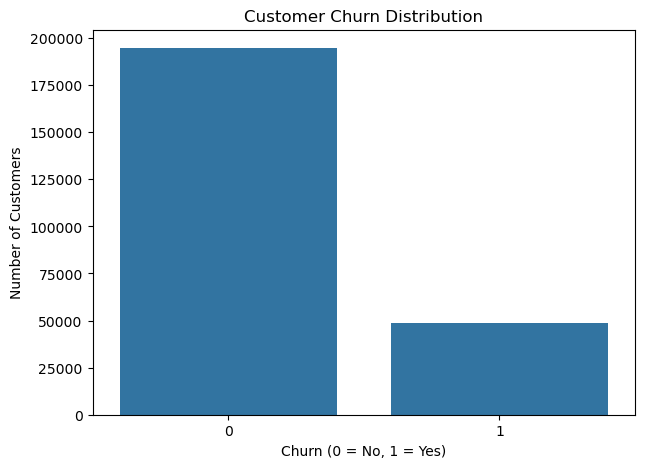

In [14]:
# Count churn categories
churn_counts = df["churn"].value_counts()

print("Churn Counts:")
print(churn_counts)

# Calculate percentage
churn_percentage = df["churn"].value_counts(normalize=True) * 100

print("\nChurn Percentage:")
display(churn_percentage)

# Visualize churn distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

Churn Count by Telecom Partner:


churn,0,1
telecom_partner,,
Airtel,48501,12404
BSNL,48663,12060
Reliance Jio,48889,12234
Vodafone,48673,12129



Churn Percentage by Telecom Partner:


churn,0,1
telecom_partner,,
Airtel,79.633856,20.366144
BSNL,80.139321,19.860679
Reliance Jio,79.984621,20.015379
Vodafone,80.051643,19.948357


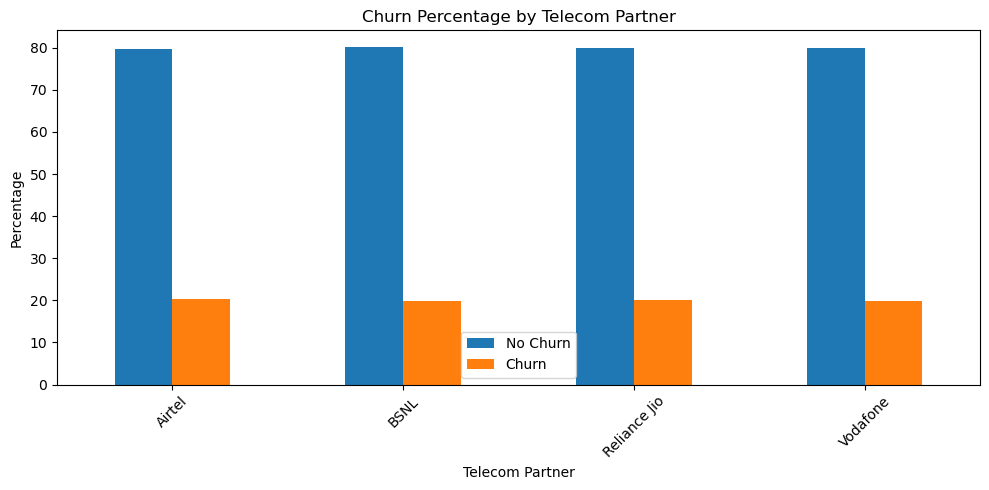

In [15]:
# Calculate churn count by telecom partner
partner_churn = pd.crosstab(
    df["telecom_partner"],
    df["churn"]
)

print("Churn Count by Telecom Partner:")
display(partner_churn)

# Calculate churn percentage by partner
partner_churn_percentage = pd.crosstab(
    df["telecom_partner"],
    df["churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Telecom Partner:")
display(partner_churn_percentage)

# Visualize churn percentage
partner_churn_percentage.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Percentage by Telecom Partner")
plt.xlabel("Telecom Partner")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(["No Churn", "Churn"])
plt.tight_layout()
plt.show()

Churn Count by Gender:


churn,0,1
gender,,
F,77771,19805
M,116955,29022



Churn Percentage by Gender:


churn,0,1
gender,,
F,79.703001,20.296999
M,80.118786,19.881214


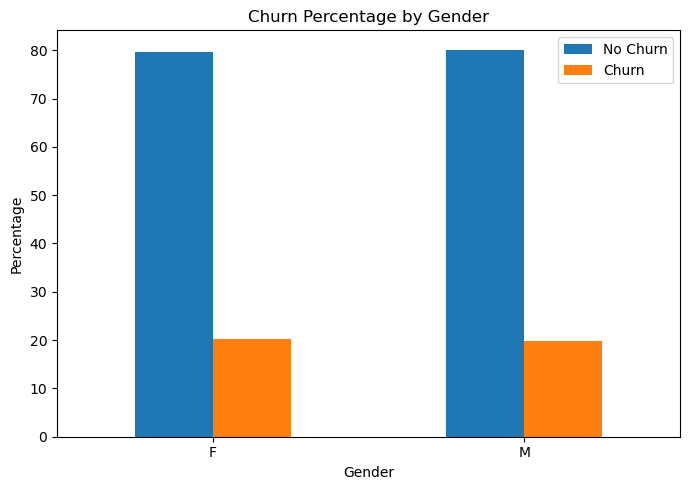

In [16]:
# Churn count by gender
gender_churn = pd.crosstab(
    df["gender"],
    df["churn"]
)

print("Churn Count by Gender:")
display(gender_churn)

# Churn percentage by gender
gender_churn_percentage = pd.crosstab(
    df["gender"],
    df["churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Gender:")
display(gender_churn_percentage)

# Visualization
gender_churn_percentage.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Percentage by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(["No Churn", "Churn"])
plt.tight_layout()
plt.show()

Churn Percentage by Age Group:


churn,0,1
age_group,,
18-25,80.062305,19.937695
26-35,79.941847,20.058153
36-45,79.823677,20.176323
46-55,80.039530,19.960470
56-65,79.966475,20.033525
66-74,79.895386,20.104614


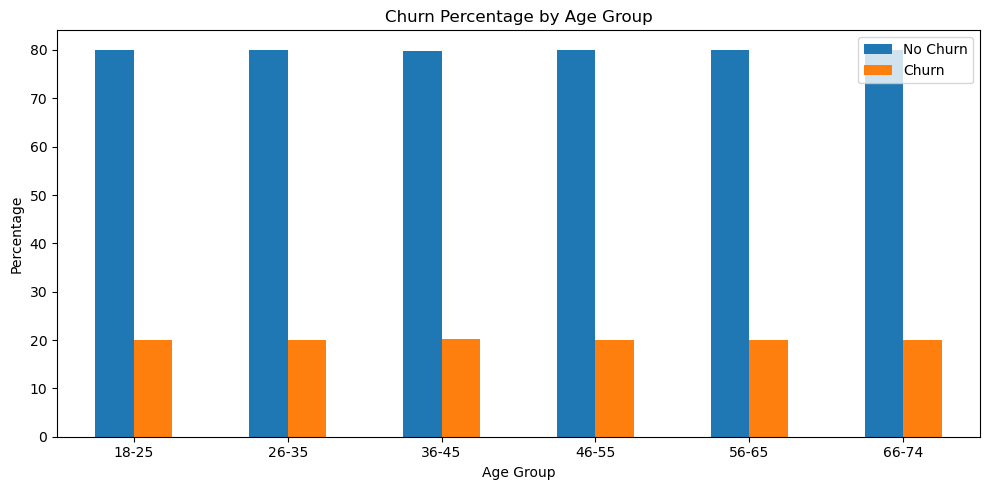

In [17]:
# Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 45, 55, 65, 75],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "66-74"
    ]
)

# Calculate churn percentage by age group
age_churn = pd.crosstab(
    df["age_group"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Percentage by Age Group:")
display(age_churn)

# Visualize results
age_churn.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(["No Churn", "Churn"])
plt.tight_layout()
plt.show()

Churn Percentage by State:


churn,0,1
state,,
Jharkhand,78.880640,21.119360
Karnataka,79.287733,20.712267
Mizoram,79.353205,20.646795
Uttarakhand,79.584463,20.415537
Himachal Pradesh,79.589956,20.410044
Madhya Pradesh,79.618918,20.381082
Assam,79.700480,20.299520
Odisha,79.752066,20.247934
Nagaland,79.771082,20.228918


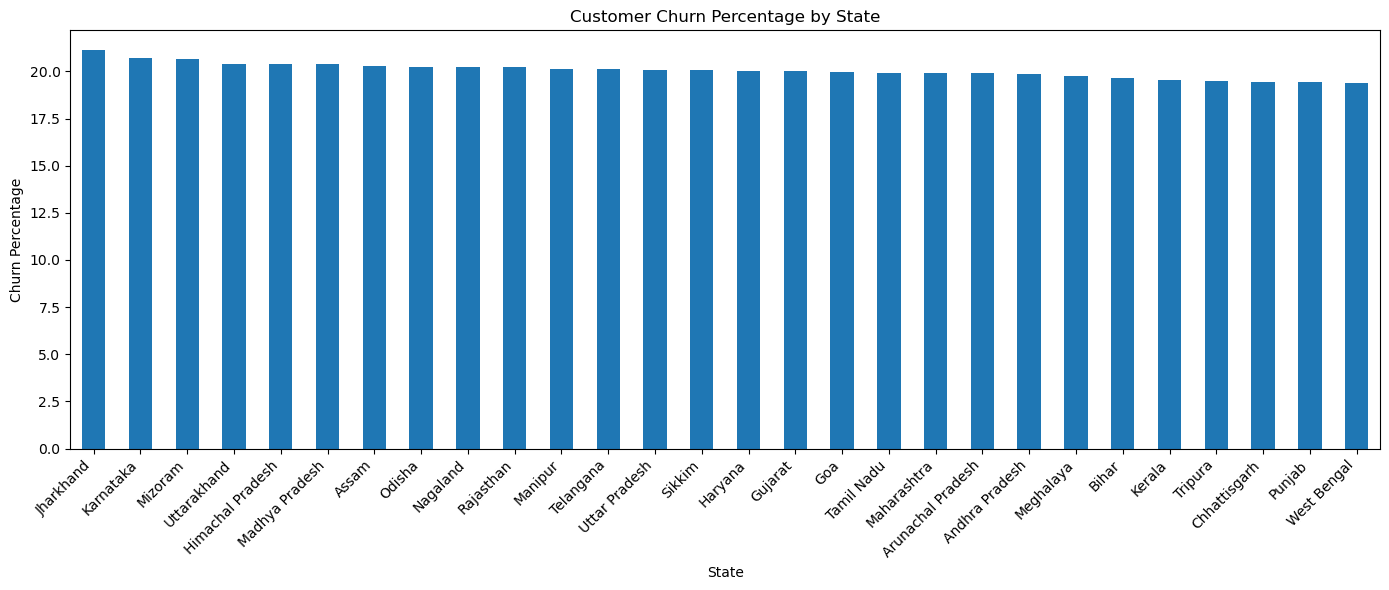

In [18]:
# Calculate churn percentage by state
state_churn = pd.crosstab(
    df["state"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Percentage by State:")
display(state_churn.sort_values(
    by=1, ascending=False
))

# Visualize churn percentage
state_churn[1].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Customer Churn Percentage by State")
plt.xlabel("State")
plt.ylabel("Churn Percentage")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Churn Count by City:


churn,0,1
city,,
Bangalore,32462,8141
Chennai,32699,8050
Delhi,32466,7990
Hyderabad,32389,8309
Kolkata,32465,8196
Mumbai,32245,8141



Churn Percentage by City:


churn,0,1
city,,
Bangalore,79.949757,20.050243
Chennai,80.244914,19.755086
Delhi,80.250148,19.749852
Hyderabad,79.583763,20.416237
Kolkata,79.843093,20.156907
Mumbai,79.842024,20.157976


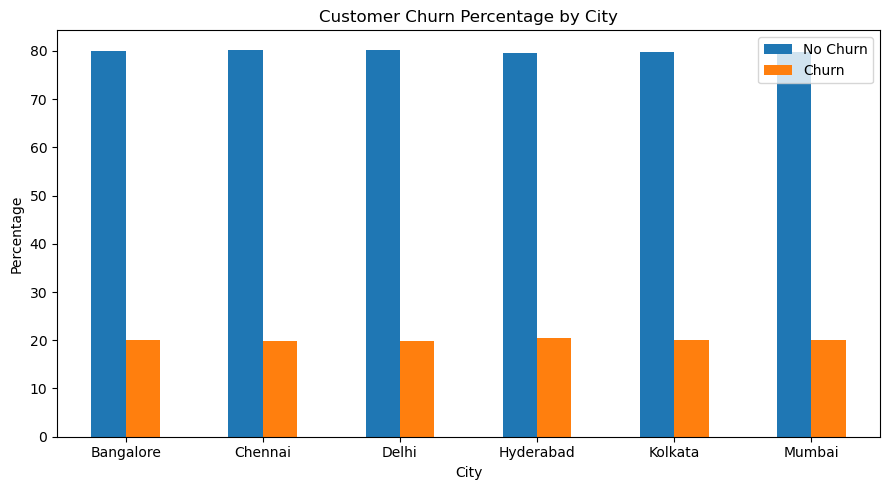

In [19]:
# Calculate churn count by city
city_churn = pd.crosstab(
    df["city"],
    df["churn"]
)

print("Churn Count by City:")
display(city_churn)

# Calculate churn percentage by city
city_churn_percentage = pd.crosstab(
    df["city"],
    df["churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by City:")
display(city_churn_percentage)

# Visualize churn percentage
city_churn_percentage.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Churn Percentage by City")
plt.xlabel("City")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(["No Churn", "Churn"])
plt.tight_layout()
plt.show()

In [20]:
# Select numerical features for analysis
numeric_features = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used"
]

# Compare mean and median values by churn
churn_numeric_analysis = df.groupby("churn")[numeric_features].agg(
    ["mean", "median"]
)

print("Numerical Feature Analysis by Churn:")
display(churn_numeric_analysis)

Numerical Feature Analysis by Churn:


age        num_dependents        estimated_salary           \
            mean median           mean median             mean   median   
churn                                                                     
0      46.070699   46.0       1.999302    2.0     85083.726934  85051.0   
1      46.105167   46.0       1.990313    2.0     84771.527495  84768.0   

      calls_made          sms_sent           data_used          
            mean median       mean median         mean  median  
churn                                                           
0      48.985590   49.0  23.968068   24.0  4992.107941  4986.0  
1      49.110083   49.0  23.855019   24.0  4997.485510  4992.0

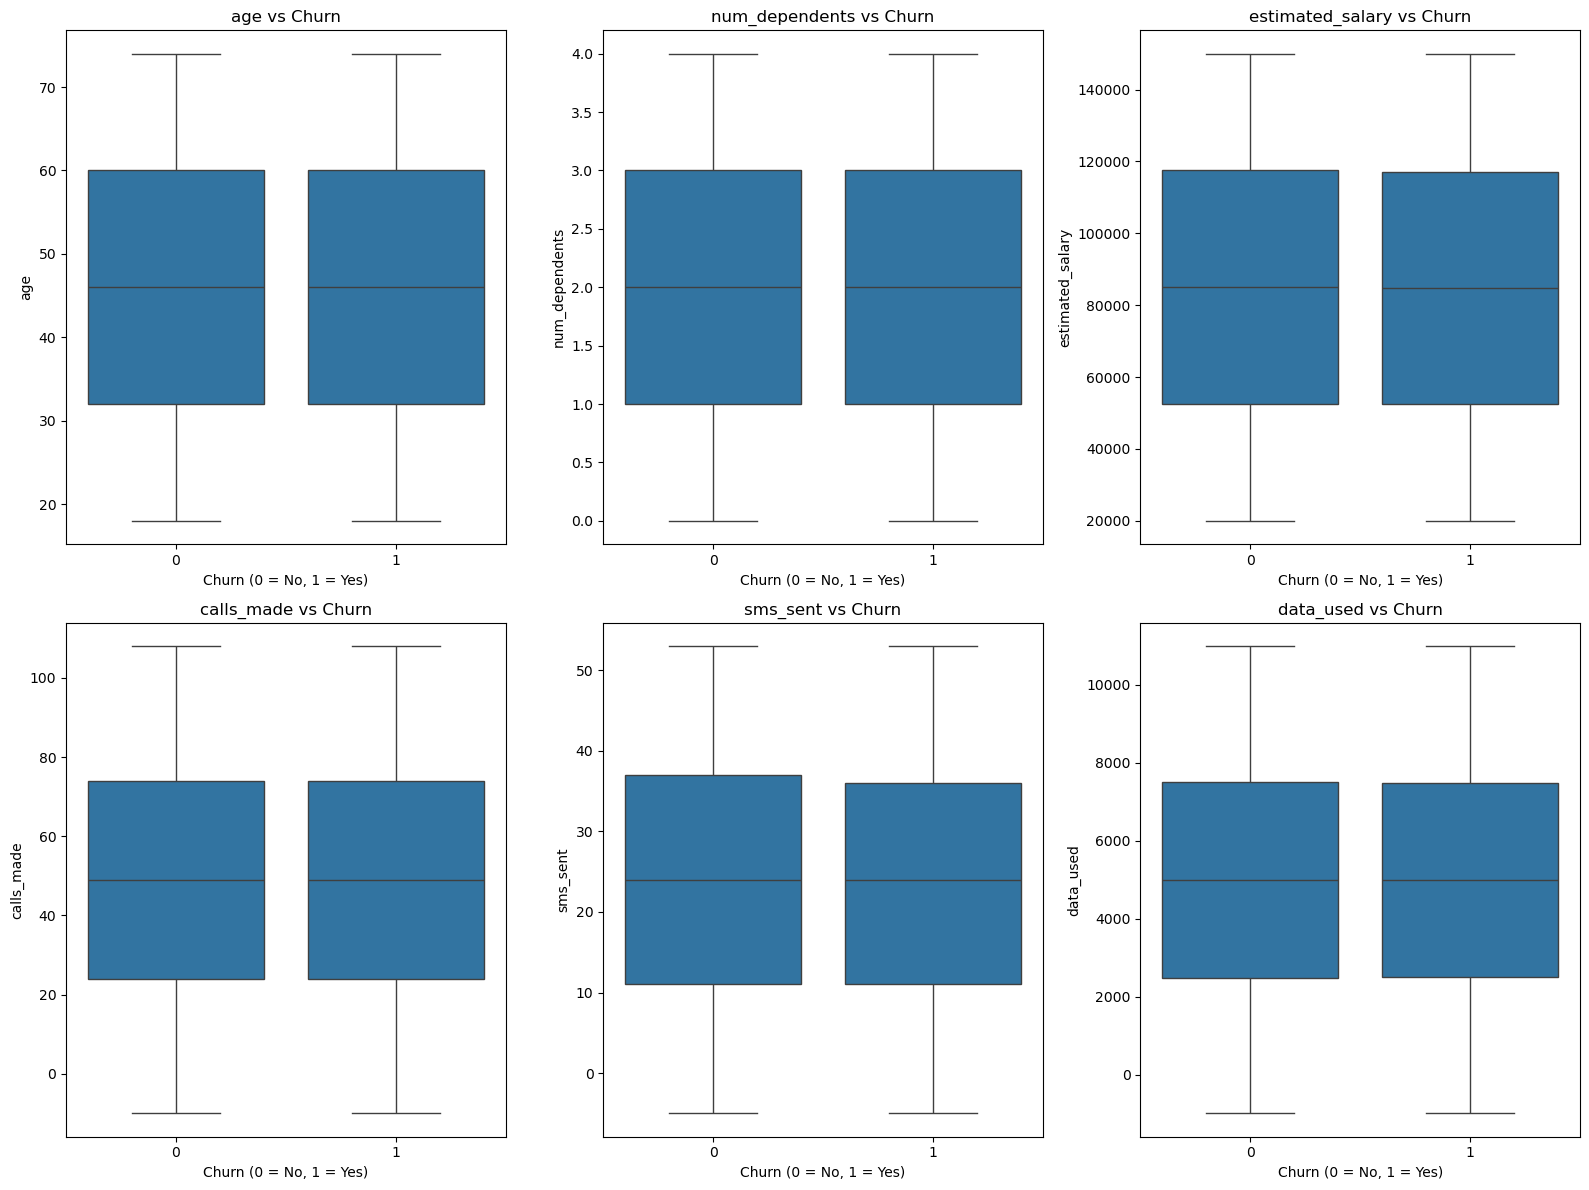

In [21]:
# Select numerical features
numeric_features = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used"
]

# Create boxplots
plt.figure(figsize=(16, 12))

for i, column in enumerate(numeric_features, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x="churn",
        y=column
    )

    plt.title(f"{column} vs Churn")
    plt.xlabel("Churn (0 = No, 1 = Yes)")
    plt.ylabel(column)

plt.tight_layout()
plt.show()

Correlation Matrix:


,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
age,1.000000,0.001462,-0.003103,-0.001399,-0.002749,0.000761,0.000839
num_dependents,0.001462,1.000000,0.002157,0.000325,0.002126,0.003177,-0.002543
estimated_salary,-0.003103,0.002157,1.000000,-0.000156,0.002720,-0.003383,-0.003332
calls_made,-0.001399,0.000325,-0.000156,1.000000,0.000035,0.001120,0.001692
sms_sent,-0.002749,0.002126,0.002720,0.000035,1.000000,-0.002878,-0.003072
data_used,0.000761,0.003177,-0.003383,0.001120,-0.002878,1.000000,0.000732
churn,0.000839,-0.002543,-0.003332,0.001692,-0.003072,0.000732,1.000000


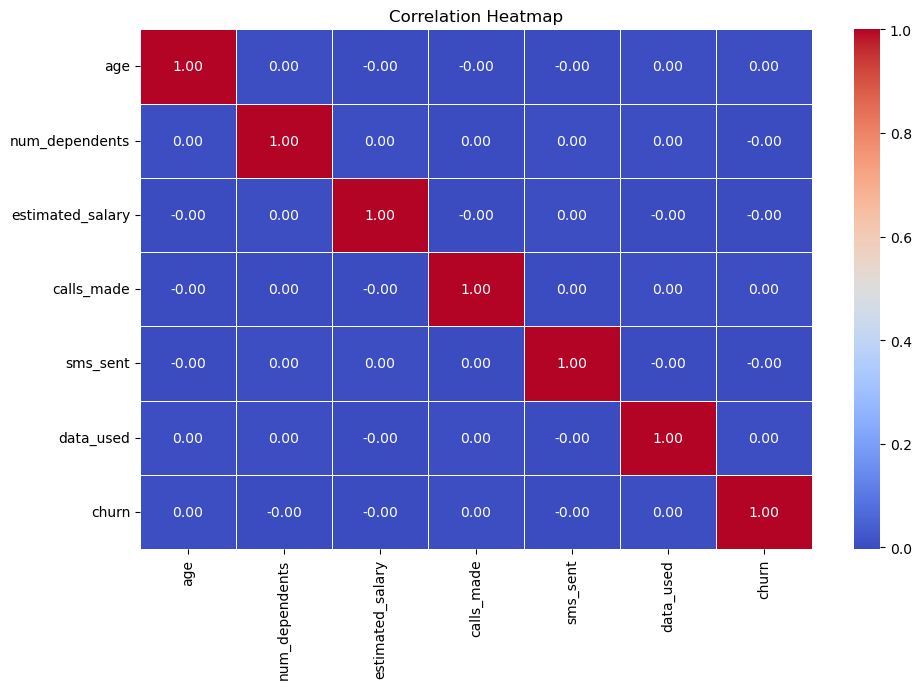

In [22]:
# Select numerical features
correlation_features = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "churn"
]

# Calculate correlation matrix
correlation_matrix = df[correlation_features].corr()

print("Correlation Matrix:")
display(correlation_matrix)

# Visualize correlation
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [23]:
# Extract year from registration date
df["registration_year"] = (
    df["date_of_registration"].dt.year
)

# Extract month from registration date
df["registration_month"] = (
    df["date_of_registration"].dt.month
)

# Display new features
print("New Features Created Successfully!")

display(
    df[
        [
            "date_of_registration",
            "registration_year",
            "registration_month"
        ]
    ].head(10)
)

New Features Created Successfully!


,date_of_registration,registration_year,registration_month
0,2020-01-01,2020,1
1,2020-01-01,2020,1
2,2020-01-01,2020,1
3,2020-01-01,2020,1
4,2020-01-01,2020,1
5,2020-01-01,2020,1
6,2020-01-01,2020,1
7,2020-01-01,2020,1
8,2020-01-01,2020,1
9,2020-01-01,2020,1


In [24]:
# Check unique registration years
print("Registration Years:")
print(sorted(df["registration_year"].unique()))

# Check unique registration months
print("\nRegistration Months:")
print(sorted(df["registration_month"].unique()))

# Check number of unique values
print("\nUnique Registration Years:",
      df["registration_year"].nunique())

print("Unique Registration Months:",
      df["registration_month"].nunique())

# Analyze churn by registration month
month_churn = pd.crosstab(
    df["registration_month"],
    df["churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Registration Month:")
display(month_churn)

Registration Years:
[np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]

Registration Months:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

Unique Registration Years: 4
Unique Registration Months: 12

Churn Percentage by Registration Month:


churn,0,1
registration_month,,
1,79.446194,20.553806
2,80.312694,19.687306
3,80.427061,19.572939
4,79.842342,20.157658
5,80.277358,19.722642
6,79.812024,20.187976
7,80.281993,19.718007
8,79.565147,20.434853
9,80.129025,19.870975


Churn Percentage by Registration Year:


churn,0,1
registration_year,,
2020,80.091896,19.908104
2021,79.831610,20.168390
2022,79.919370,20.080630
2023,79.991862,20.008138


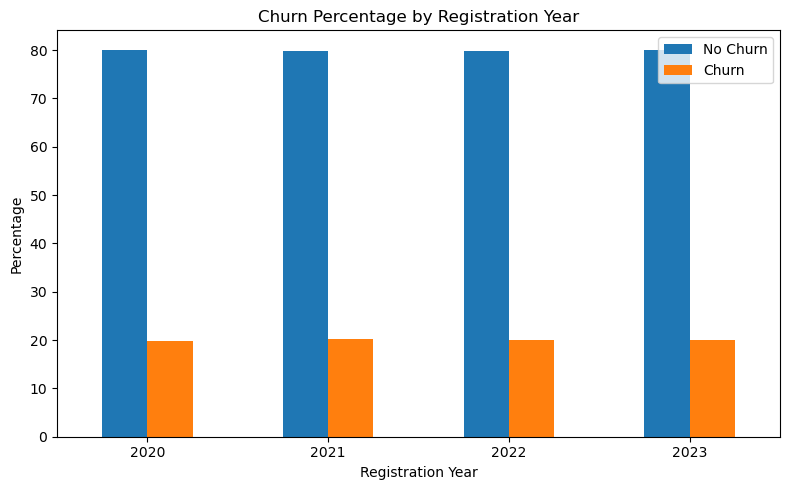

In [25]:
# Calculate churn percentage by registration year
year_churn = pd.crosstab(
    df["registration_year"],
    df["churn"],
    normalize="index"
) * 100

print("Churn Percentage by Registration Year:")
display(year_churn)

# Visualize results
year_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Percentage by Registration Year")
plt.xlabel("Registration Year")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(["No Churn", "Churn"])
plt.tight_layout()
plt.show()

In [26]:
# Check unique values
print("Unique Customer IDs:",
      df["customer_id"].nunique())

print("\nUnique Pincodes:",
      df["pincode"].nunique())

print("\nTotal Records:", len(df))

# Check customer ID uniqueness
print("\nCustomer ID is unique:",
      df["customer_id"].is_unique)

Unique Customer IDs: 243553

Unique Pincodes: 213442

Total Records: 243553

Customer ID is unique: True


In [27]:
# Create a separate copy for modelling
df_model = df.copy()

# Remove unnecessary columns
df_model.drop(
    columns=[
        "customer_id",
        "pincode",
        "date_of_registration",
        "age_group"
    ],
    inplace=True
)

# Display remaining columns
print("Remaining Columns:")
print(df_model.columns.tolist())

# Check new dataset shape
print("\nModelling Dataset Shape:", df_model.shape)

# Display first five records
display(df_model.head())

Remaining Columns:
['telecom_partner', 'gender', 'age', 'state', 'city', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn', 'registration_year', 'registration_month']

Modelling Dataset Shape: (243553, 13)


,telecom_partner,gender,age,state,city,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn,registration_year,registration_month
0,Reliance Jio,F,25,Karnataka,Kolkata,4,124962,44,45,-361,0,2020,1
1,Reliance Jio,F,55,Mizoram,Mumbai,2,130556,62,39,5973,0,2020,1
2,Vodafone,F,57,Arunachal Pradesh,Delhi,0,148828,49,24,193,1,2020,1
3,BSNL,M,46,Tamil Nadu,Kolkata,1,38722,80,25,9377,1,2020,1
4,BSNL,F,26,Tripura,Delhi,2,55098,78,15,1393,0,2020,1


In [28]:
# Identify categorical columns
categorical_cols = df_model.select_dtypes(
    include=["object"]
).columns.tolist()

# Identify numerical columns
numerical_cols = df_model.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_cols)

print("\nNumerical Columns:")
print(numerical_cols)

print("\nCategorical Feature Count:",
      len(categorical_cols))

print("Numerical Feature Count:",
      len(numerical_cols))

# Check missing values after preparation
print("\nTotal Missing Values:",
      df_model.isnull().sum().sum())

Categorical Columns:
['telecom_partner', 'gender', 'state', 'city']

Numerical Columns:
['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn']

Categorical Feature Count: 4
Numerical Feature Count: 7

Total Missing Values: 0


In [29]:
# Separate target variable
y = df_model["churn"]

# Remove target from input features
X = df_model.drop(columns=["churn"])

# Identify categorical features
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Identify all numerical features
numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

print("\nCategorical Features:")
print(categorical_cols)

print("\nNumerical Features:")
print(numerical_cols)

print("\nTotal Input Features:", X.shape[1])

Input Features (X): (243553, 12)
Target Variable (y): (243553,)

Categorical Features:
['telecom_partner', 'gender', 'state', 'city']

Numerical Features:
['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'registration_year', 'registration_month']

Total Input Features: 12


In [30]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Check churn distribution
print("\nTraining Churn Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Churn Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Data Shape: (194842, 12)
Testing Data Shape: (48711, 12)

Training Target Shape: (194842,)
Testing Target Shape: (48711,)

Training Churn Distribution:
churn
0    79.951961
1    20.048039
Name: proportion, dtype: float64

Testing Churn Distribution:
churn
0    79.953193
1    20.046807
Name: proportion, dtype: float64


In [31]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Create One-Hot Encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", encoder, categorical_cols)
    ],
    remainder="passthrough"
)

# Fit on training data and transform both datasets
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoding Completed Successfully!")

print("\nTraining Data Shape:", X_train_encoded.shape)
print("Testing Data Shape:", X_test_encoded.shape)

Encoding Completed Successfully!

Training Data Shape: (194842, 48)
Testing Data Shape: (48711, 48)


In [32]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", StandardScaler(), numerical_cols)
    ]
)

# Fit on training data and transform both datasets
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Feature Scaling Completed Successfully!")

print("\nTraining Data Shape:", X_train_prepared.shape)
print("Testing Data Shape:", X_test_prepared.shape)

Feature Scaling Completed Successfully!

Training Data Shape: (194842, 48)
Testing Data Shape: (48711, 48)


In [33]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_prepared, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict churn on testing data
y_pred_lr = lr_model.predict(X_test_prepared)

# Calculate evaluation metrics
print("Logistic Regression Evaluation")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Evaluation
--------------------------------
Accuracy: 0.7995319332388988
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Confusion Matrix:
[[38946     0]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



In [35]:
import numpy as np

# Get probability of churn (class 1)
y_prob_lr = lr_model.predict_proba(X_test_prepared)[:, 1]

print("Minimum Probability:", np.min(y_prob_lr))
print("Maximum Probability:", np.max(y_prob_lr))

print("\nProbability Percentiles:")
print(np.percentile(y_prob_lr, [25, 50, 75, 90, 95, 99]))

print("\nPredictions at Default Threshold (0.5):")
print("Predicted Churn Customers:", np.sum(y_prob_lr >= 0.5))

Minimum Probability: 0.1777382158901279
Maximum Probability: 0.22332106321637926

Probability Percentiles:
[0.19637957 0.20048082 0.20455723 0.20830059 0.21055584 0.21477091]

Predictions at Default Threshold (0.5):
Predicted Churn Customers: 0


In [36]:
from sklearn.metrics import confusion_matrix, classification_report

# Experiment with a lower threshold
threshold = 0.20

y_pred_threshold = (y_prob_lr >= threshold).astype(int)

print("Threshold:", threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_threshold))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_threshold))

Threshold: 0.2

Confusion Matrix:
[[18286 20660]
 [ 4542  5223]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.47      0.59     38946
           1       0.20      0.53      0.29      9765

    accuracy                           0.48     48711
   macro avg       0.50      0.50      0.44     48711
weighted avg       0.68      0.48      0.53     48711



In [37]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_prepared, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict customer churn
y_pred_rf = rf_model.predict(X_test_prepared)

# Calculate evaluation metrics
print("Random Forest Evaluation")
print("-------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Evaluation
-------------------------
Accuracy: 0.7995114039949909
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Confusion Matrix:
[[38945     1]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



In [39]:
import numpy as np

# Get churn probabilities
y_prob_rf = rf_model.predict_proba(X_test_prepared)[:, 1]

print("Minimum Probability:", np.min(y_prob_rf))
print("Maximum Probability:", np.max(y_prob_rf))

print("\nProbability Percentiles:")
print(np.percentile(y_prob_rf, [25, 50, 75, 90, 95, 99]))

print("\nPredicted Churn at Default Threshold:")
print(np.sum(y_prob_rf >= 0.5))


Minimum Probability: 0.04
Maximum Probability: 0.51

Probability Percentiles:
[0.17 0.2  0.24 0.27 0.29 0.34]

Predicted Churn at Default Threshold:
1


In [40]:
from sklearn.metrics import confusion_matrix, classification_report

# Set experimental threshold
threshold = 0.20

# Generate predictions
y_pred_rf_threshold = (y_prob_rf >= threshold).astype(int)

print("Random Forest Threshold:", threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_threshold))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_threshold))

Random Forest Threshold: 0.2

Confusion Matrix:
[[17896 21050]
 [ 4477  5288]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.46      0.58     38946
           1       0.20      0.54      0.29      9765

    accuracy                           0.48     48711
   macro avg       0.50      0.50      0.44     48711
weighted avg       0.68      0.48      0.53     48711



In [41]:
from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train_prepared, y_train)

print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict customer churn
y_pred_gb = gb_model.predict(X_test_prepared)

# Calculate evaluation metrics
print("Gradient Boosting Evaluation")
print("-----------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Evaluation
-----------------------------
Accuracy: 0.799470345507175
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Confusion Matrix:
[[38943     3]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



In [43]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_gb, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_gb, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_gb, zero_division=0)
    ]
})

print(model_comparison)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression  0.799532        0.0     0.0       0.0
1        Random Forest  0.799511        0.0     0.0       0.0
2    Gradient Boosting  0.799470        0.0     0.0       0.0


In [44]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Calculate probability predictions
y_prob_lr = lr_model.predict_proba(X_test_prepared)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test_prepared)[:, 1]
y_prob_gb = gb_model.predict_proba(X_test_prepared)[:, 1]

# Create comparison
auc_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ],
    "Average Precision": [
        average_precision_score(y_test, y_prob_lr),
        average_precision_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_gb)
    ]
})

print(auc_comparison)

                 Model   ROC-AUC  Average Precision
0  Logistic Regression  0.505815           0.205052
1        Random Forest  0.501760           0.201621
2    Gradient Boosting  0.497559           0.199376


In [45]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif

# Prepare numerical features
scaler_mi = StandardScaler()
X_num_mi = scaler_mi.fit_transform(X_train[numerical_cols])

# Encode categorical features
encoder_mi = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_cat_mi = encoder_mi.fit_transform(X_train[categorical_cols])

# Combine numerical and categorical features
X_mi = np.hstack([X_num_mi, X_cat_mi])

# Identify discrete categorical columns
discrete_mask = np.array(
    [False] * len(numerical_cols) +
    [True] * len(categorical_cols)
)

# Calculate Mutual Information
mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

# Create feature importance table
feature_names = numerical_cols + categorical_cols

mi_results = pd.DataFrame({
    "Feature": feature_names,
    "Mutual Information": mi_scores
})

mi_results = mi_results.sort_values(
    by="Mutual Information",
    ascending=False
)

print(mi_results)

               Feature  Mutual Information
6    registration_year            0.007848
1       num_dependents            0.004246
7   registration_month            0.002994
5            data_used            0.001182
3           calls_made            0.000460
10               state            0.000041
11                city            0.000021
9               gender            0.000016
8      telecom_partner            0.000005
0                  age            0.000000
2     estimated_salary            0.000000
4             sms_sent            0.000000


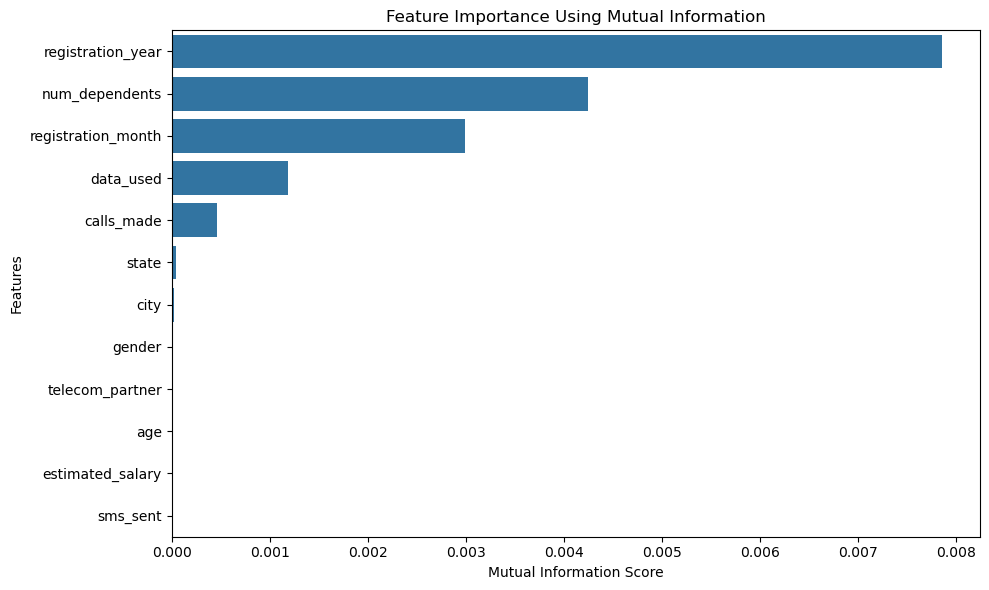

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=mi_results,
    x="Mutual Information",
    y="Feature"
)

plt.title("Feature Importance Using Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [47]:
year_churn = df.groupby("registration_year")["churn"].agg(
    ["count", "sum", "mean"]
)

year_churn["Churn_Percentage"] = year_churn["mean"] * 100

print(year_churn)

                   count    sum      mean  Churn_Percentage
registration_year                                          
2020               73126  14558  0.199081         19.908104
2021               72926  14708  0.201684         20.168390
2022               72926  14644  0.200806         20.080630
2023               24575   4917  0.200081         20.008138


In [48]:
dependents_churn = df.groupby("num_dependents")["churn"].agg(
    ["count", "sum", "mean"]
)

dependents_churn["Churn_Percentage"] = (
    dependents_churn["mean"] * 100
)

print(dependents_churn)

                count   sum      mean  Churn_Percentage
num_dependents                                         
0               48927  9900  0.202342         20.234227
1               48701  9815  0.201536         20.153590
2               48605  9719  0.199959         19.995885
3               48694  9644  0.198053         19.805315
4               48626  9749  0.200489         20.048945


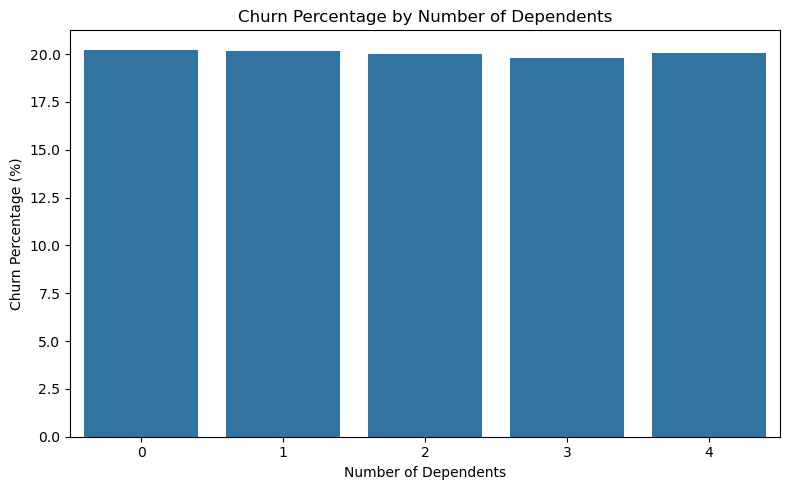

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=dependents_churn.reset_index(),
    x="num_dependents",
    y="Churn_Percentage"
)

plt.title("Churn Percentage by Number of Dependents")
plt.xlabel("Number of Dependents")
plt.ylabel("Churn Percentage (%)")

plt.tight_layout()
plt.show()

### Feature Importance Analysis

Mutual Information analysis was performed to identify the
relationship between input features and customer churn.

Registration Year and Number of Dependents received the
highest Mutual Information scores. However, their scores
were very low.

Further analysis showed that churn percentages were nearly
similar across registration years and dependent groups.

Therefore, the available features show limited predictive
information about customer churn.

In [50]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train_prepared, y_train)

y_dummy_pred = dummy_model.predict(X_test_prepared)

print("Baseline Accuracy:", accuracy_score(y_test, y_dummy_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_dummy_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_dummy_pred, zero_division=0))

Baseline Accuracy: 0.7995319332388988

Confusion Matrix:
[[38946     0]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



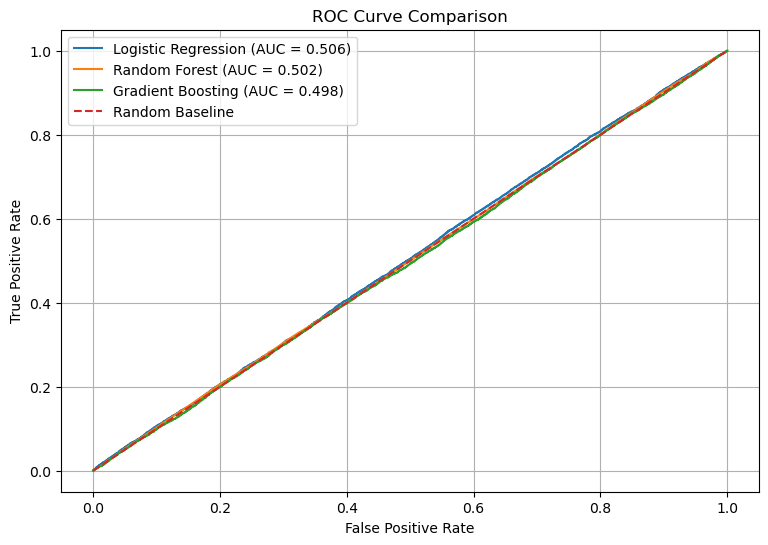

In [51]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

plt.figure(figsize=(9, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test_prepared)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()

### ROC Curve Analysis

ROC curves were plotted to compare the performance of
Logistic Regression, Random Forest, and Gradient Boosting.

The ROC-AUC scores were:

- Logistic Regression: 0.506
- Random Forest: 0.502
- Gradient Boosting: 0.498

All three models performed close to the random baseline
(AUC = 0.500).

Therefore, the models show very limited ability to
distinguish between churn and non-churn customers.

Further investigation of the dataset and target variable
is required before selecting a final model.

In [52]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "Baseline": dummy_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_prepared)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_prepared)[:, 1]
    else:
        y_prob = None

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else None,
        "Average Precision": average_precision_score(y_test, y_prob) if y_prob is not None else None
    })

final_comparison = pd.DataFrame(results)

print(final_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  \
0  Logistic Regression    0.7995        0.0     0.0       0.0   0.5058   
1        Random Forest    0.7995        0.0     0.0       0.0   0.5018   
2    Gradient Boosting    0.7995        0.0     0.0       0.0   0.4976   
3             Baseline    0.7995        0.0     0.0       0.0   0.5000   

   Average Precision  
0             0.2051  
1             0.2016  
2             0.1994  
3             0.2005  


### Final Model Performance Comparison

Four models were evaluated: Logistic Regression, Random
Forest, Gradient Boosting, and Dummy Classifier.

All models achieved approximately 79.95% accuracy.
However, precision, recall, and F1-score for the churn
class were zero at the default classification threshold.

Logistic Regression achieved the highest ROC-AUC of 0.5058,
which is very close to random guessing.

The results indicate that the current dataset features
provide insufficient predictive information for reliable
customer churn prediction.

Further investigation of the dataset and target variable
is required before selecting a final model.

In [53]:
final_comparison.to_csv(
    "customer_churn_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


### Project Limitations

1. The dataset features show very weak relationships with the churn target.
2. All three machine learning models performed close to random guessing.
3. The default classification threshold resulted in zero churn detection.
4. Several negative values were identified in calls_made, sms_sent,
   and data_used. These require clarification.
5. The connected dataset schema differs from the schema described
   in the original DataMites project PDF.
6. The dataset source and churn target definition need confirmation.

Further data validation and feature investigation are required
to improve model performance.

In [54]:
print("Unique Churn Values:")
print(df["churn"].unique())

print("\nChurn Value Counts:")
print(df["churn"].value_counts())

print("\nChurn Percentage:")
print(df["churn"].value_counts(normalize=True) * 100)

Unique Churn Values:
[0 1]

Churn Value Counts:
churn
0    194726
1     48827
Name: count, dtype: int64

Churn Percentage:
churn
0    79.952208
1    20.047792
Name: proportion, dtype: float64


In [55]:
partner_churn = df.groupby("telecom_partner")["churn"].agg(
    ["count", "sum", "mean"]
)

partner_churn["Churn_Percentage"] = partner_churn["mean"] * 100

print(partner_churn)

                 count    sum      mean  Churn_Percentage
telecom_partner                                          
Airtel           60905  12404  0.203661         20.366144
BSNL             60723  12060  0.198607         19.860679
Reliance Jio     61123  12234  0.200154         20.015379
Vodafone         60802  12129  0.199484         19.948357


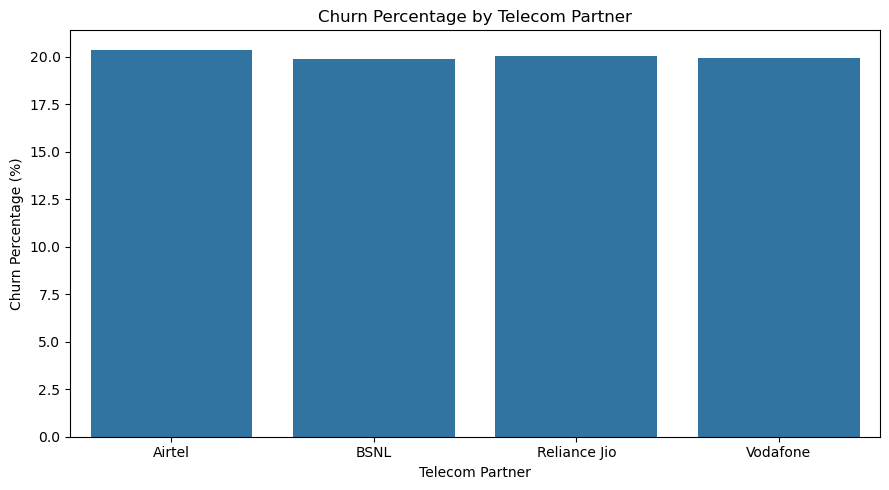

In [56]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=partner_churn.reset_index(),
    x="telecom_partner",
    y="Churn_Percentage"
)

plt.title("Churn Percentage by Telecom Partner")
plt.xlabel("Telecom Partner")
plt.ylabel("Churn Percentage (%)")

plt.tight_layout()
plt.show()

In [57]:
gender_churn = df.groupby("gender")["churn"].agg(
    ["count", "sum", "mean"]
)

gender_churn["Churn_Percentage"] = gender_churn["mean"] * 100

print(gender_churn)

         count    sum      mean  Churn_Percentage
gender                                           
F        97576  19805  0.202970         20.296999
M       145977  29022  0.198812         19.881214


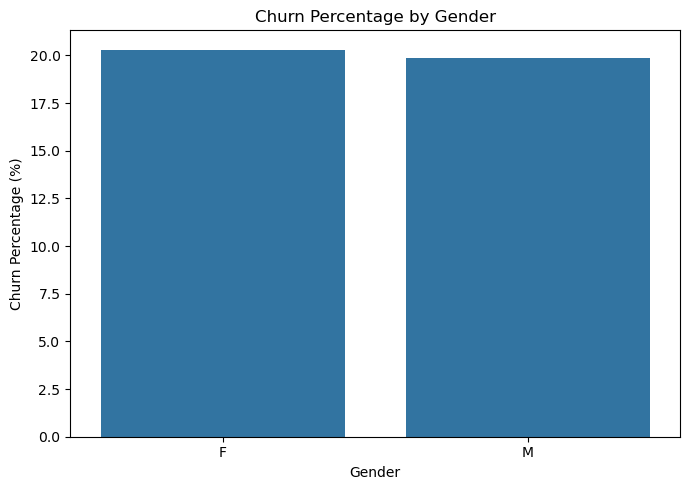

In [58]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=gender_churn.reset_index(),
    x="gender",
    y="Churn_Percentage"
)

plt.title("Churn Percentage by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Percentage (%)")

plt.tight_layout()
plt.show()

In [59]:
state_churn = df.groupby("state")["churn"].agg(
    ["count", "sum", "mean"]
)

state_churn["Churn_Percentage"] = state_churn["mean"] * 100

state_churn = state_churn.sort_values(
    by="Churn_Percentage",
    ascending=False
)

print(state_churn)

                   count   sum      mean  Churn_Percentage
state                                                     
Jharkhand           8755  1849  0.211194         21.119360
Karnataka           8845  1832  0.207123         20.712267
Mizoram             8689  1794  0.206468         20.646795
Uttarakhand         8856  1808  0.204155         20.415537
Himachal Pradesh    8682  1772  0.204100         20.410044
Madhya Pradesh      8817  1797  0.203811         20.381082
Assam               8547  1735  0.202995         20.299520
Odisha              8712  1764  0.202479         20.247934
Nagaland            8562  1732  0.202289         20.228918
Rajasthan           8750  1769  0.202171         20.217143
Manipur             8651  1740  0.201133         20.113282
Telangana           8689  1747  0.201059         20.105881
Uttar Pradesh       8742  1755  0.200755         20.075498
Sikkim              8689  1744  0.200714         20.071355
Haryana             8740  1751  0.200343         20.0343

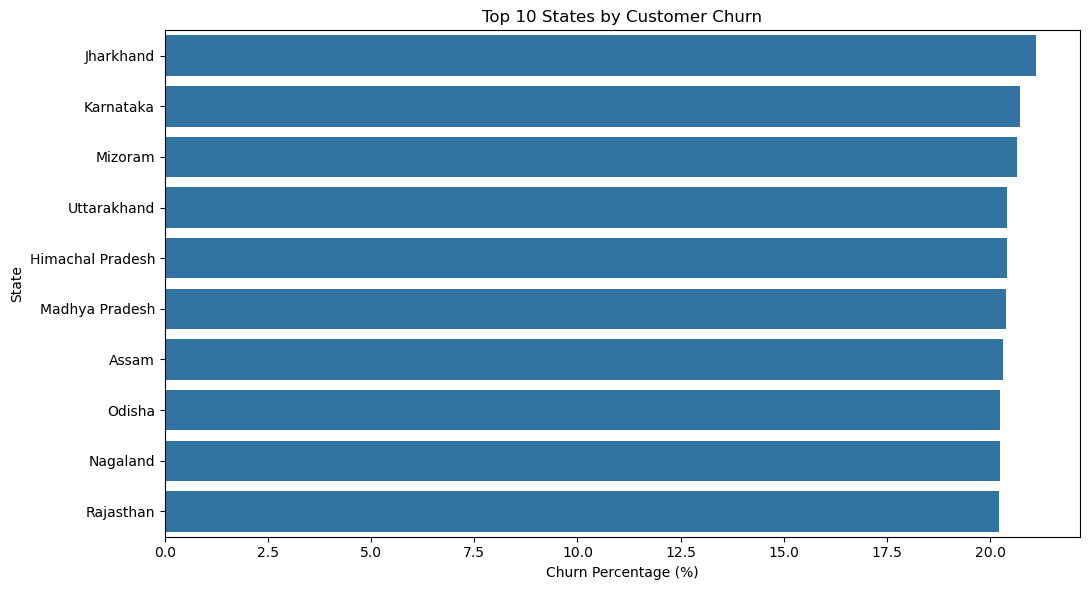

In [60]:
top_states = state_churn.head(10).reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_states,
    x="Churn_Percentage",
    y="state"
)

plt.title("Top 10 States by Customer Churn")
plt.xlabel("Churn Percentage (%)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [61]:
city_churn = df.groupby("city")["churn"].agg(
    ["count", "sum", "mean"]
)

city_churn["Churn_Percentage"] = city_churn["mean"] * 100

city_churn = city_churn.sort_values(
    by="Churn_Percentage",
    ascending=False
)

print(city_churn.head(15))

           count   sum      mean  Churn_Percentage
city                                              
Hyderabad  40698  8309  0.204162         20.416237
Mumbai     40386  8141  0.201580         20.157976
Kolkata    40661  8196  0.201569         20.156907
Bangalore  40603  8141  0.200502         20.050243
Chennai    40749  8050  0.197551         19.755086
Delhi      40456  7990  0.197499         19.749852


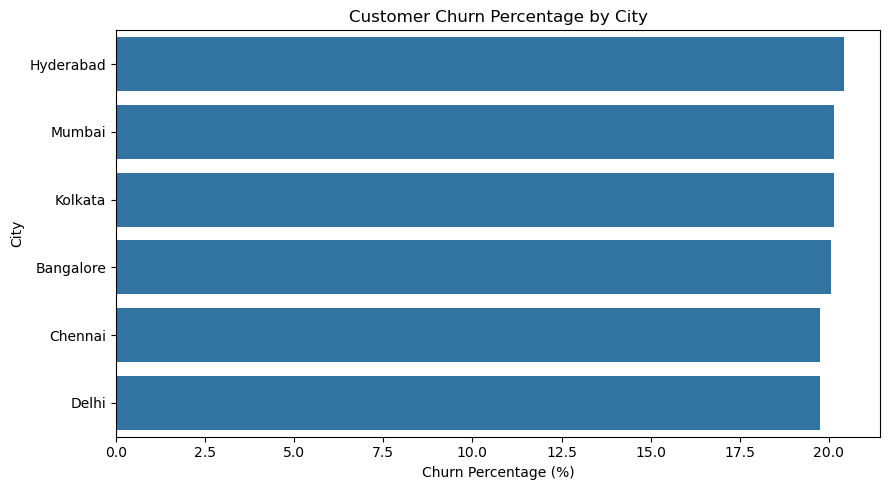

In [62]:
city_plot = city_churn.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=city_plot,
    x="Churn_Percentage",
    y="city"
)

plt.title("Customer Churn Percentage by City")
plt.xlabel("Churn Percentage (%)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [63]:
numeric_features = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used"
]

numerical_churn_analysis = df.groupby("churn")[numeric_features].mean().T

numerical_churn_analysis.columns = [
    "Not Churned",
    "Churned"
]

numerical_churn_analysis["Difference"] = (
    numerical_churn_analysis["Churned"]
    - numerical_churn_analysis["Not Churned"]
)

print(numerical_churn_analysis)

                   Not Churned       Churned  Difference
age                  46.070699     46.105167    0.034468
num_dependents        1.999302      1.990313   -0.008989
estimated_salary  85083.726934  84771.527495 -312.199439
calls_made           48.985590     49.110083    0.124493
sms_sent             23.968068     23.855019   -0.113049
data_used          4992.107941   4997.485510    5.377569


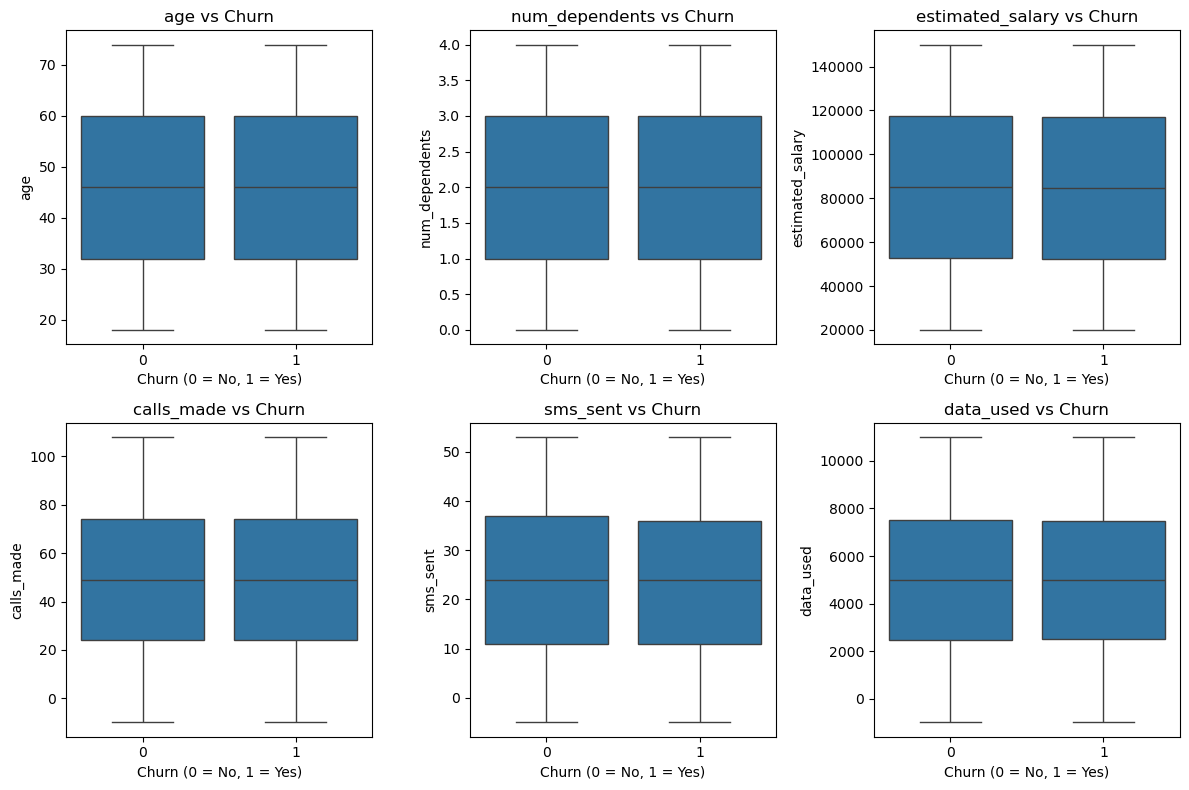

In [64]:
plt.figure(figsize=(12, 8))

for i, feature in enumerate(numeric_features, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x="churn",
        y=feature
    )

    plt.title(f"{feature} vs Churn")
    plt.xlabel("Churn (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

In [65]:
negative_counts = (df[numeric_features] < 0).sum()

print("Negative Values in Numerical Features:")
print(negative_counts)

Negative Values in Numerical Features:
age                    0
num_dependents         0
estimated_salary       0
calls_made          6713
sms_sent            7375
data_used           6050
dtype: int64


In [66]:
for feature in ["calls_made", "sms_sent", "data_used"]:

    print(f"\nNegative values in {feature}:")

    print(
        df[df[feature] < 0]
        .groupby("churn")
        .size()
    )


Negative values in calls_made:
churn
0    5351
1    1362
dtype: int64

Negative values in sms_sent:
churn
0    5839
1    1536
dtype: int64

Negative values in data_used:
churn
0    4796
1    1254
dtype: int64


In [67]:
negative_mask = (df[["calls_made", "sms_sent", "data_used"]] < 0).any(axis=1)

print("Total affected records:", negative_mask.sum())

print("Percentage affected:", round(
    negative_mask.mean() * 100, 2
), "%")

Total affected records: 19587
Percentage affected: 8.04 %


### Data Quality Analysis – Negative Values

During data validation, negative values were identified in
three numerical features:

- calls_made: 6,713 negative values
- sms_sent: 7,375 negative values
- data_used: 6,050 negative values

A total of 19,587 unique customer records (8.04% of the
dataset) contain at least one negative value.

Negative values occur in both churn classes.

These values were not replaced or removed because their
meaning is not confirmed. Clarification from the dataset
provider is required before applying data-cleaning methods.

In [68]:
df["negative_value_flag"] = (
    (df[["calls_made", "sms_sent", "data_used"]] < 0)
    .any(axis=1)
)

negative_churn = df.groupby("negative_value_flag")["churn"].agg(
    ["count", "sum", "mean"]
)

negative_churn["Churn_Percentage"] = (
    negative_churn["mean"] * 100
)

print(negative_churn)

                      count    sum      mean  Churn_Percentage
negative_value_flag                                           
False                223966  44796  0.200013         20.001250
True                  19587   4031  0.205800         20.579977


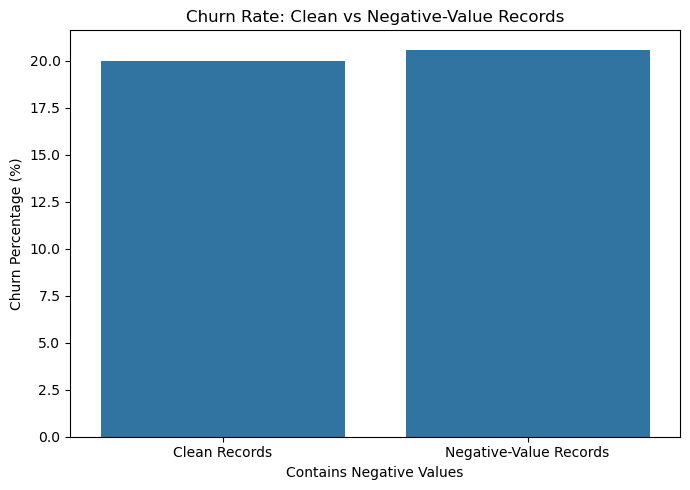

In [69]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=negative_churn.reset_index(),
    x="negative_value_flag",
    y="Churn_Percentage"
)

plt.title("Churn Rate: Clean vs Negative-Value Records")
plt.xlabel("Contains Negative Values")
plt.ylabel("Churn Percentage (%)")

plt.xticks(
    [0, 1],
    ["Clean Records", "Negative-Value Records"]
)

plt.tight_layout()
plt.show()

In [70]:
print("Total Customer Records:", len(df))

print("Unique Customer IDs:", df["customer_id"].nunique())

print("Duplicate Customer IDs:", df["customer_id"].duplicated().sum())

Total Customer Records: 243553
Unique Customer IDs: 243553
Duplicate Customer IDs: 0


In [71]:
print("Total Duplicate Rows:", df.duplicated().sum())

print("Dataset Shape:", df.shape)

Total Duplicate Rows: 0
Dataset Shape: (243553, 18)


In [72]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made              0
sms_sent                0
data_used               0
churn                   0
age_group               0
registration_year       0
registration_month      0
negative_value_flag     0
dtype: int64

Total Missing Values: 0


In [73]:
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
customer_id                      int64
telecom_partner                 object
gender                          object
age                              int64
state                           object
city                            object
pincode                          int64
date_of_registration    datetime64[ns]
num_dependents                   int64
estimated_salary                 int64
calls_made                       int64
sms_sent                         int64
data_used                        int64
churn                            int64
age_group                     category
registration_year                int32
registration_month               int32
negative_value_flag               bool
dtype: object


In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243553 entries, 0 to 243552
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   customer_id           243553 non-null  int64         
 1   telecom_partner       243553 non-null  object        
 2   gender                243553 non-null  object        
 3   age                   243553 non-null  int64         
 4   state                 243553 non-null  object        
 5   city                  243553 non-null  object        
 6   pincode               243553 non-null  int64         
 7   date_of_registration  243553 non-null  datetime64[ns]
 8   num_dependents        243553 non-null  int64         
 9   estimated_salary      243553 non-null  int64         
 10  calls_made            243553 non-null  int64         
 11  sms_sent              243553 non-null  int64         
 12  data_used             243553 non-null  int64         
 13 

In [75]:
print("Churn Value Counts:")
print(df["churn"].value_counts())

print("\nChurn Percentages:")
print(df["churn"].value_counts(normalize=True) * 100)

Churn Value Counts:
churn
0    194726
1     48827
Name: count, dtype: int64

Churn Percentages:
churn
0    79.952208
1    20.047792
Name: proportion, dtype: float64


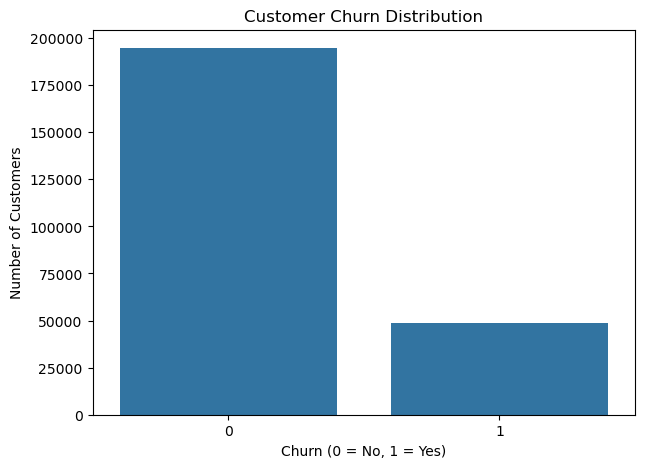

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

### Target Variable Analysis – Customer Churn

The target variable `churn` contains two classes: 0 and 1.

- Class 0 (Not Churned): 194,726 customers (79.95%).
- Class 1 (Churned): 48,827 customers (20.05%).

The dataset has a moderate class imbalance, with more customers belonging to the non-churn category.

Therefore, model evaluation will focus on Precision, Recall, F1-score, ROC-AUC and Average Precision, along with Accuracy.

In [77]:
categorical_columns = ["telecom_partner", "gender", "state", "city"]

for col in categorical_columns:
    print(f"\n{col}:")
    print("Unique values:", df[col].nunique())
    print(df[col].unique())


telecom_partner:
Unique values: 4
['Reliance Jio' 'Vodafone' 'BSNL' 'Airtel']

gender:
Unique values: 2
['F' 'M']

state:
Unique values: 28
['Karnataka' 'Mizoram' 'Arunachal Pradesh' 'Tamil Nadu' 'Tripura'
 'Uttarakhand' 'Himachal Pradesh' 'Rajasthan' 'Odisha' 'Uttar Pradesh'
 'Chhattisgarh' 'Madhya Pradesh' 'Manipur' 'Goa' 'West Bengal' 'Gujarat'
 'Telangana' 'Maharashtra' 'Haryana' 'Andhra Pradesh' 'Sikkim' 'Assam'
 'Jharkhand' 'Kerala' 'Punjab' 'Nagaland' 'Bihar' 'Meghalaya']

city:
Unique values: 6
['Kolkata' 'Mumbai' 'Delhi' 'Chennai' 'Hyderabad' 'Bangalore']


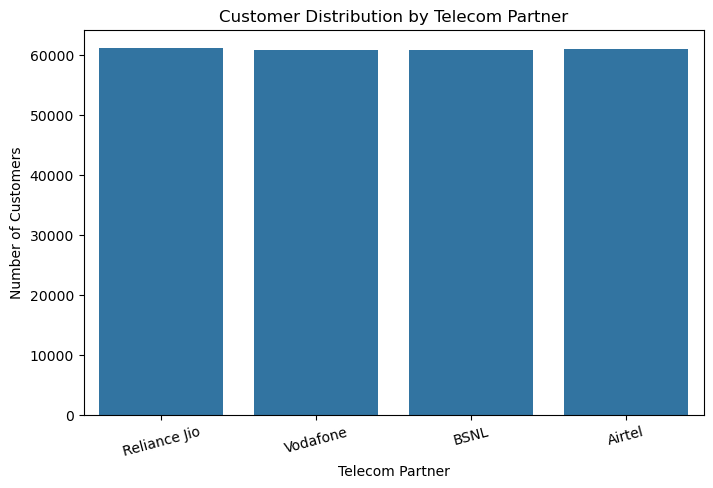

In [78]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="telecom_partner")

plt.title("Customer Distribution by Telecom Partner")
plt.xlabel("Telecom Partner")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

In [79]:
partner_churn = df.groupby("telecom_partner")["churn"].mean() * 100

print("Churn Rate by Telecom Partner:")
print(partner_churn.sort_values(ascending=False))

Churn Rate by Telecom Partner:
telecom_partner
Airtel          20.366144
Reliance Jio    20.015379
Vodafone        19.948357
BSNL            19.860679
Name: churn, dtype: float64


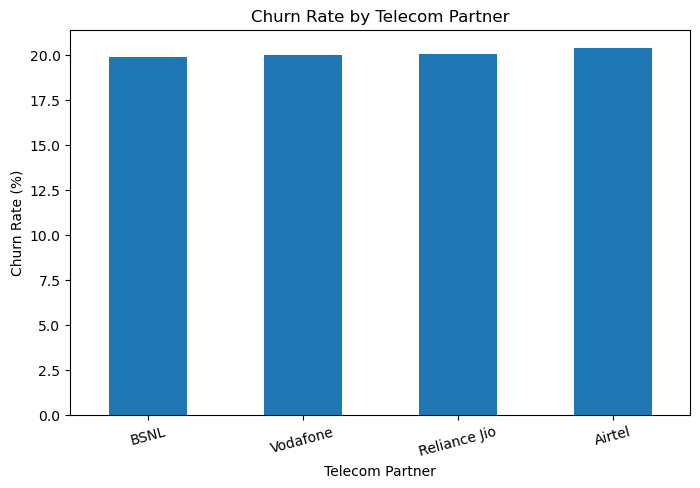

In [80]:
plt.figure(figsize=(8, 5))

partner_churn.sort_values().plot(kind="bar")

plt.title("Churn Rate by Telecom Partner")
plt.xlabel("Telecom Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.show()

In [81]:
gender_churn = df.groupby("gender")["churn"].mean() * 100

print("Churn Rate by Gender:")
print(gender_churn)

Churn Rate by Gender:
gender
F    20.296999
M    19.881214
Name: churn, dtype: float64


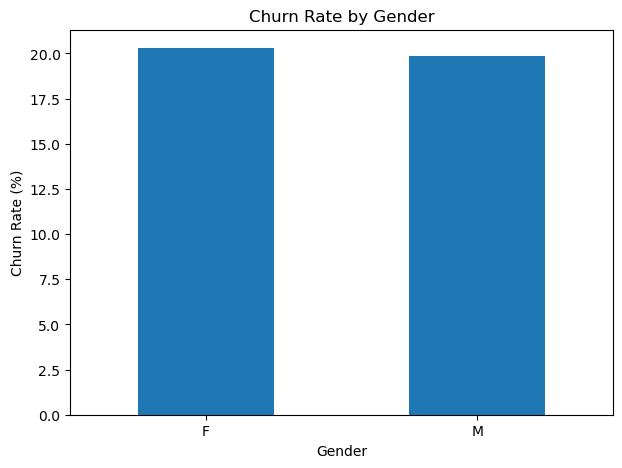

In [82]:
plt.figure(figsize=(7, 5))

gender_churn.plot(kind="bar")

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [83]:
state_churn = df.groupby("state")["churn"].mean() * 100

print("Churn Rate by State:")
print(state_churn.sort_values(ascending=False))

Churn Rate by State:
state
Jharkhand            21.119360
Karnataka            20.712267
Mizoram              20.646795
Uttarakhand          20.415537
Himachal Pradesh     20.410044
Madhya Pradesh       20.381082
Assam                20.299520
Odisha               20.247934
Nagaland             20.228918
Rajasthan            20.217143
Manipur              20.113282
Telangana            20.105881
Uttar Pradesh        20.075498
Sikkim               20.071355
Haryana              20.034325
Gujarat              20.023229
Goa                  19.956292
Tamil Nadu           19.935765
Maharashtra          19.909297
Arunachal Pradesh    19.892657
Andhra Pradesh       19.852006
Meghalaya            19.748964
Bihar                19.633963
Kerala               19.530086
Tripura              19.480370
Chhattisgarh         19.430679
Punjab               19.425127
West Bengal          19.400373
Name: churn, dtype: float64


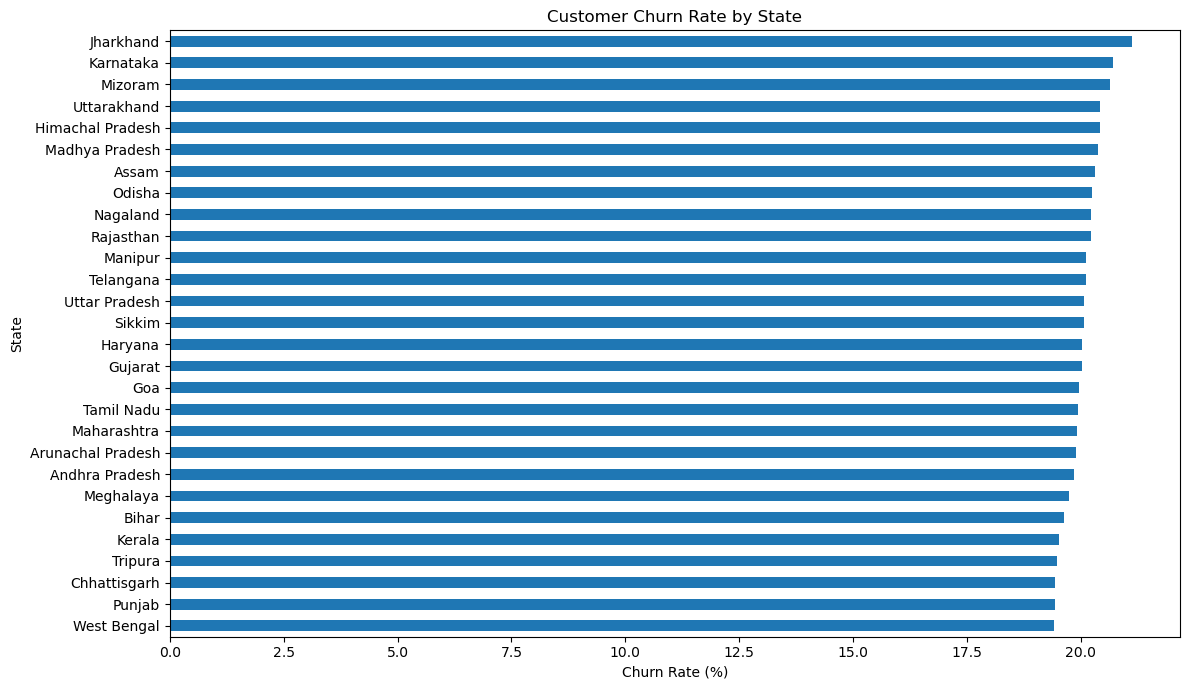

In [84]:
plt.figure(figsize=(12, 7))

state_churn.sort_values().plot(kind="barh")

plt.title("Customer Churn Rate by State")
plt.xlabel("Churn Rate (%)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [85]:
city_churn = df.groupby("city")["churn"].mean() * 100

print("Churn Rate by City:")
print(city_churn.sort_values(ascending=False))


Churn Rate by City:
city
Hyderabad    20.416237
Mumbai       20.157976
Kolkata      20.156907
Bangalore    20.050243
Chennai      19.755086
Delhi        19.749852
Name: churn, dtype: float64


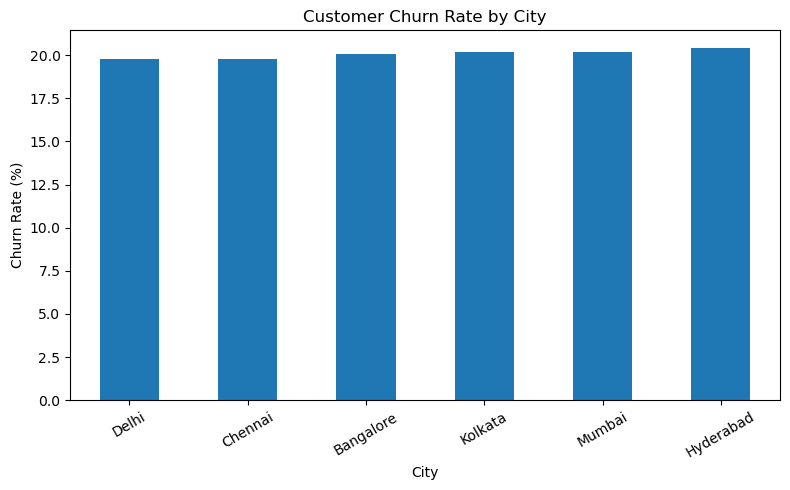

In [86]:
plt.figure(figsize=(8, 5))

city_churn.sort_values().plot(kind="bar")

plt.title("Customer Churn Rate by City")
plt.xlabel("City")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [87]:
numerical_columns = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used"
]

print("Average Values by Churn Status:")

print(
    df.groupby("churn")[numerical_columns]
    .mean()
    .T
)

Average Values by Churn Status:
churn                        0             1
age                  46.070699     46.105167
num_dependents        1.999302      1.990313
estimated_salary  85083.726934  84771.527495
calls_made           48.985590     49.110083
sms_sent             23.968068     23.855019
data_used          4992.107941   4997.485510


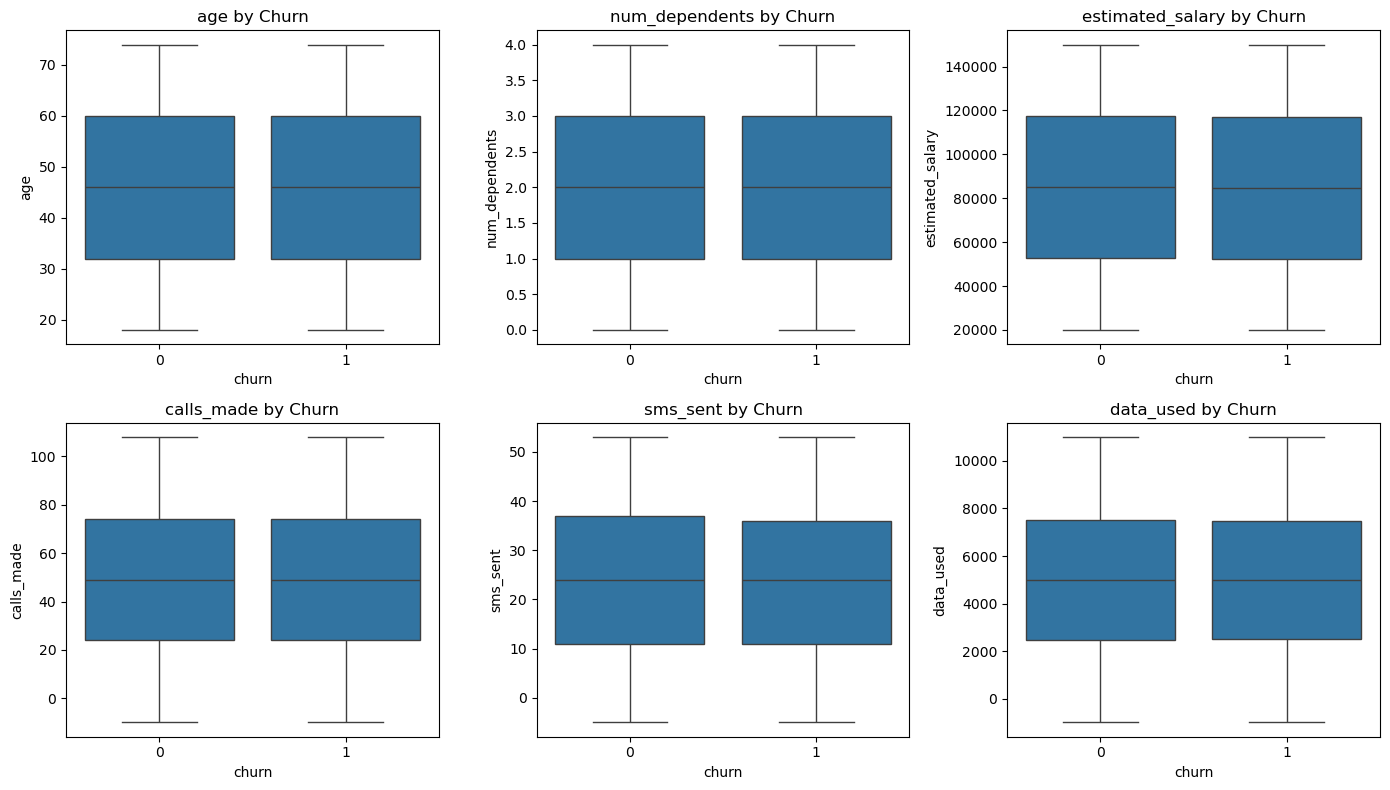

In [88]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(data=df, x="churn", y=col)
    plt.title(f"{col} by Churn")

plt.tight_layout()
plt.show()

In [89]:
negative_counts = (df[["calls_made", "sms_sent", "data_used"]] < 0).sum()

print("Negative Values in Numerical Columns:")
print(negative_counts)

Negative Values in Numerical Columns:
calls_made    6713
sms_sent      7375
data_used     6050
dtype: int64


In [90]:
for col in ["calls_made", "sms_sent", "data_used"]:
    print(f"\n{col}")
    print(df[df[col] < 0].groupby("churn").size())


calls_made
churn
0    5351
1    1362
dtype: int64

sms_sent
churn
0    5839
1    1536
dtype: int64

data_used
churn
0    4796
1    1254
dtype: int64


In [91]:
negative_records = (
    (df[["calls_made", "sms_sent", "data_used"]] < 0)
    .any(axis=1)
    .sum()
)

print("Total Records with Negative Values:", negative_records)

print("Percentage of Affected Records:",
      round((negative_records / len(df)) * 100, 2), "%")

Total Records with Negative Values: 19587
Percentage of Affected Records: 8.04 %


In [92]:
df["negative_value_flag"] = (
    (df[["calls_made", "sms_sent", "data_used"]] < 0)
    .any(axis=1)
)

negative_churn = (
    df.groupby("negative_value_flag")["churn"]
    .agg(["count", "sum", "mean"])
)

negative_churn["mean"] = negative_churn["mean"] * 100

print("Churn Analysis by Negative Value Flag:")
print(negative_churn)

Churn Analysis by Negative Value Flag:
                      count    sum       mean
negative_value_flag                          
False                223966  44796  20.001250
True                  19587   4031  20.579977


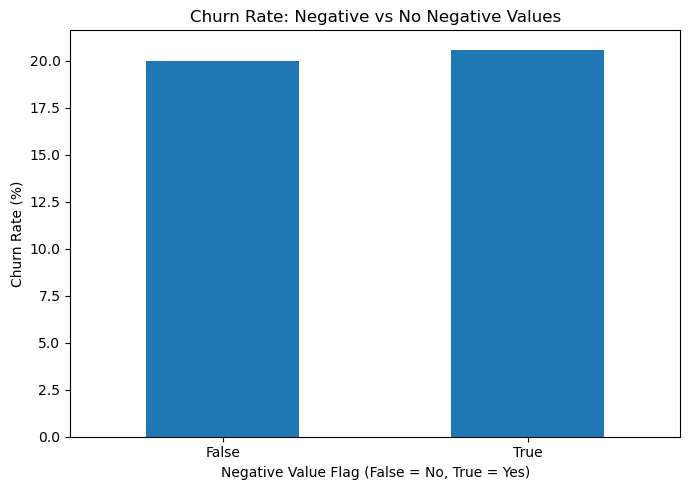

In [93]:
plt.figure(figsize=(7, 5))

negative_churn["mean"].plot(kind="bar")

plt.title("Churn Rate: Negative vs No Negative Values")
plt.xlabel("Negative Value Flag (False = No, True = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Negative Value Analysis

During data quality analysis, negative values were identified in three numerical columns:

- `calls_made`: 6,713 negative values.
- `sms_sent`: 7,375 negative values.
- `data_used`: 6,050 negative values.

A total of 19,587 unique customer records (8.04%) contain at least one negative value.

The churn rate was approximately 20.00% for records without negative values and 20.58% for records containing negative values.

The difference is small. Negative values will not be automatically replaced or removed because their meaning requires confirmation from the dataset documentation or project mentor.

In [94]:
correlation = df[
    ["age", "num_dependents", "estimated_salary",
     "calls_made", "sms_sent", "data_used", "churn"]
].corr()

print("Correlation with Churn:")
print(correlation["churn"].sort_values(ascending=False))

Correlation with Churn:
churn               1.000000
calls_made          0.001692
age                 0.000839
data_used           0.000732
num_dependents     -0.002543
sms_sent           -0.003072
estimated_salary   -0.003332
Name: churn, dtype: float64


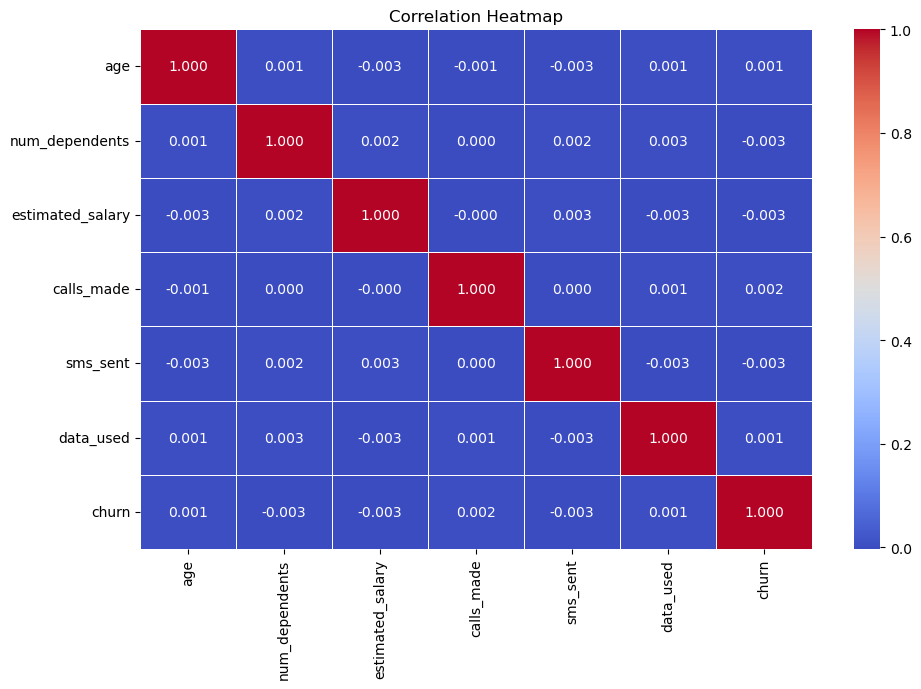

In [95]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [96]:
from sklearn.feature_selection import mutual_info_classif

X_mi = df_model.drop(columns=["churn"])
y_mi = df_model["churn"]

mi_scores = mutual_info_classif(
    X_mi.select_dtypes(include=["number"]),
    y_mi,
    random_state=42
)

mi_results = pd.Series(
    mi_scores,
    index=X_mi.select_dtypes(include=["number"]).columns
).sort_values(ascending=False)

print("Mutual Information Scores:")
print(mi_results)

Mutual Information Scores:
registration_year     0.015179
num_dependents        0.008355
registration_month    0.003012
age                   0.001394
data_used             0.000895
sms_sent              0.000794
estimated_salary      0.000000
calls_made            0.000000
dtype: float64


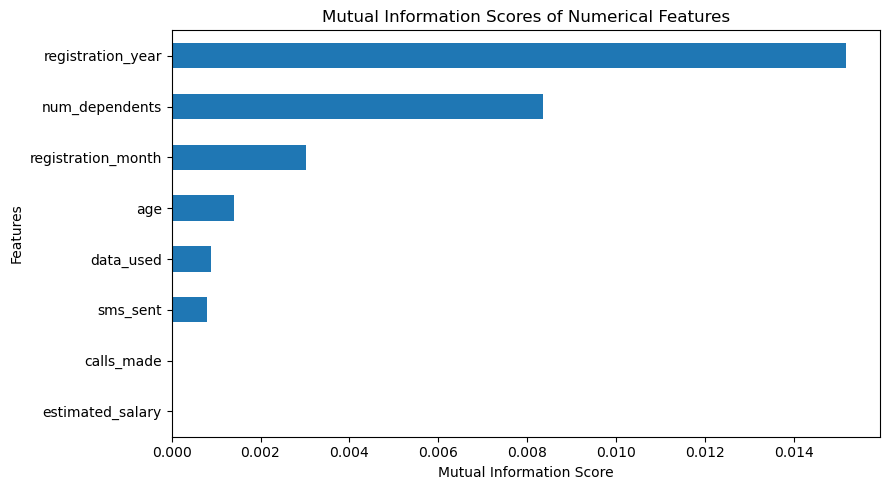

In [97]:
plt.figure(figsize=(9, 5))

mi_results.sort_values().plot(kind="barh")

plt.title("Mutual Information Scores of Numerical Features")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [98]:
year_churn = (
    df.groupby("registration_year")["churn"]
    .agg(["count", "sum", "mean"])
)

year_churn["mean"] = year_churn["mean"] * 100

print("Churn Analysis by Registration Year:")
print(year_churn)

Churn Analysis by Registration Year:
                   count    sum       mean
registration_year                         
2020               73126  14558  19.908104
2021               72926  14708  20.168390
2022               72926  14644  20.080630
2023               24575   4917  20.008138


In [99]:
dependent_churn = (
    df.groupby("num_dependents")["churn"]
    .agg(["count", "sum", "mean"])
)

dependent_churn["mean"] = dependent_churn["mean"] * 100

print("Churn Analysis by Number of Dependents:")
print(dependent_churn)

Churn Analysis by Number of Dependents:
                count   sum       mean
num_dependents                        
0               48927  9900  20.234227
1               48701  9815  20.153590
2               48605  9719  19.995885
3               48694  9644  19.805315
4               48626  9749  20.048945


In [100]:
month_churn = (
    df.groupby("registration_month")["churn"]
    .agg(["count", "sum", "mean"])
)

month_churn["mean"] = month_churn["mean"] * 100

print("Churn Analysis by Registration Month:")
print(month_churn)

Churn Analysis by Registration Month:
                    count   sum       mean
registration_month                        
1                   24774  5092  20.553806
2                   22578  4445  19.687306
3                   24774  4849  19.572939
4                   23976  4833  20.157658
5                   19181  3783  19.722642
6                   17981  3630  20.187976
7                   18582  3664  19.718007
8                   18581  3797  20.434853
9                   17981  3573  19.870975
10                  18581  3706  19.945105
11                  17982  3717  20.670671
12                  18582  3738  20.116242


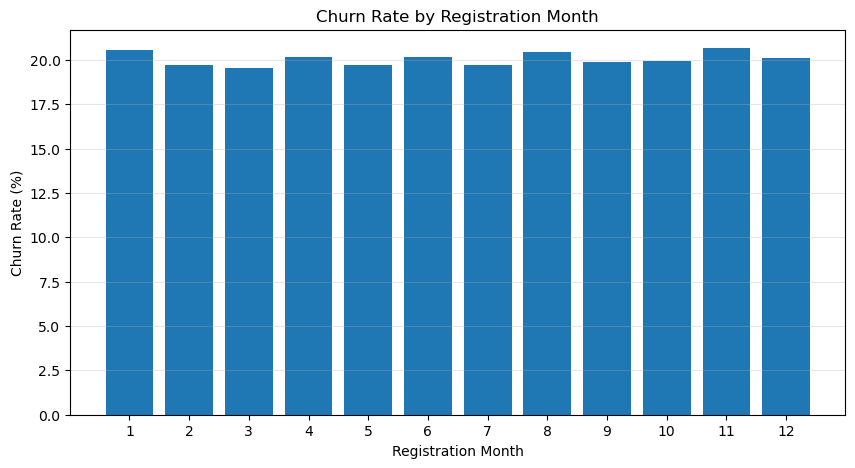

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(month_churn.index, month_churn["mean"])

plt.title("Churn Rate by Registration Month")
plt.xlabel("Registration Month")
plt.ylabel("Churn Rate (%)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [102]:
print("FINAL EDA SUMMARY")
print("-" * 40)

print("Total Customers:", len(df))
print("Total Churned Customers:", df["churn"].sum())
print("Overall Churn Rate:", round(df["churn"].mean() * 100, 2), "%")

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nNumerical Features:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nCategorical Features:")
print(df.select_dtypes(include="object").columns.tolist())

FINAL EDA SUMMARY
----------------------------------------
Total Customers: 243553
Total Churned Customers: 48827
Overall Churn Rate: 20.05 %

Missing Values: 0
Duplicate Rows: 0

Numerical Features:
['customer_id', 'age', 'pincode', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn', 'registration_year', 'registration_month']

Categorical Features:
['telecom_partner', 'gender', 'state', 'city']


### Exploratory Data Analysis – Conclusion

The Customer Churn dataset contains 243,553 customer records and 14 original columns. The overall customer churn rate is 20.05%.

The dataset has no missing values or duplicate records. Analysis was performed on numerical and categorical features, including age, salary, telecom partner, gender, state, city, registration year, and registration month.

The churn rates across most categories are very similar. Numerical features also show very small differences between churned and non-churned customers. Registration year and number of dependents showed relatively higher mutual information scores, but their predictive relationships remain weak.

Negative values were identified in calls_made, sms_sent, and data_used. These values require clarification before deciding whether to correct or retain them.

Overall, the EDA indicates that the available features may have limited ability to explain customer churn. Further validation and feature investigation are required before finalizing the predictive model.

In [103]:
print("All Dataset Columns:")
print(df.columns.tolist())

print("\nColumns to Exclude:")
print([
    "customer_id",
    "pincode",
    "date_of_registration",
    "age_group",
    "negative_value_flag"
])

print("\nTarget Column:")
print("churn")

All Dataset Columns:
['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn', 'age_group', 'registration_year', 'registration_month', 'negative_value_flag']

Columns to Exclude:
['customer_id', 'pincode', 'date_of_registration', 'age_group', 'negative_value_flag']

Target Column:
churn


In [104]:
df_model = df.drop(columns=[
    "customer_id",
    "pincode",
    "date_of_registration",
    "age_group",
    "negative_value_flag"
])

print("Final Model Dataset Shape:", df_model.shape)

print("\nFinal Model Columns:")
print(df_model.columns.tolist())

print("\nMissing Values:")
print(df_model.isnull().sum().sum())

Final Model Dataset Shape: (243553, 13)

Final Model Columns:
['telecom_partner', 'gender', 'age', 'state', 'city', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn', 'registration_year', 'registration_month']

Missing Values:
0


In [105]:
X = df_model.drop("churn", axis=1)
y = df_model["churn"]

print("Features (X) Shape:", X.shape)
print("Target (y) Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features (X) Shape: (243553, 12)
Target (y) Shape: (243553,)

Target Distribution:
churn
0    194726
1     48827
Name: count, dtype: int64


In [106]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (194842, 12)
Testing Features: (48711, 12)

Training Target Distribution:
churn
0    79.951961
1    20.048039
Name: proportion, dtype: float64

Testing Target Distribution:
churn
0    79.953193
1    20.046807
Name: proportion, dtype: float64


In [107]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numeric_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used']

Categorical Features:
['telecom_partner', 'gender', 'state', 'city']

Total Numerical Features: 6
Total Categorical Features: 4


In [108]:
numeric_features = X_train.select_dtypes(
    include=["int32", "int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numeric_features))
print("Total Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'registration_year', 'registration_month']

Categorical Features:
['telecom_partner', 'gender', 'state', 'city']

Total Numerical Features: 8
Total Categorical Features: 4


In [109]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [110]:
X_train_prepared = preprocessor.fit_transform(X_train)

print("Training Data Preprocessed Successfully!")
print("Original Training Shape:", X_train.shape)
print("Prepared Training Shape:", X_train_prepared.shape)

Training Data Preprocessed Successfully!
Original Training Shape: (194842, 12)
Prepared Training Shape: (194842, 48)


In [111]:
X_test_prepared = preprocessor.transform(X_test)

print("Testing Data Preprocessed Successfully!")
print("Original Testing Shape:", X_test.shape)
print("Prepared Testing Shape:", X_test_prepared.shape)

Testing Data Preprocessed Successfully!
Original Testing Shape: (48711, 12)
Prepared Testing Shape: (48711, 48)


In [112]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_prepared, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [113]:
y_pred_lr = lr_model.predict(X_test_prepared)

print("Logistic Regression Predictions:")
print(y_pred_lr[:20])

print("\nActual Values:")
print(y_test[:20].values)


Logistic Regression Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Actual Values:
[0 1 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0]


In [114]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.7995319332388988

Confusion Matrix:
[[38946     0]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



In [115]:
from sklearn.metrics import roc_auc_score

y_prob_lr = lr_model.predict_proba(X_test_prepared)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression ROC-AUC:", roc_auc_lr)

Logistic Regression ROC-AUC: 0.5058154595822135


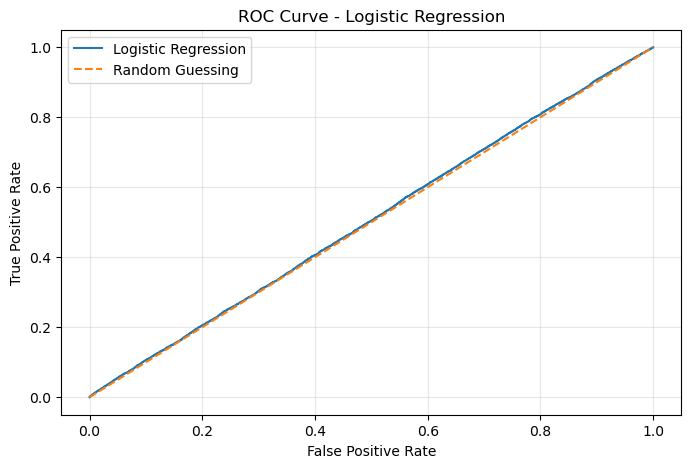

In [116]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob_lr)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [117]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_prepared, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [118]:
y_pred_rf = rf_model.predict(X_test_prepared)

print("Random Forest Predictions:")
print(y_pred_rf[:20])

print("\nActual Values:")
print(y_test[:20].values)

Random Forest Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Actual Values:
[0 1 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0]


In [119]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.7995114039949909

Confusion Matrix:
[[38945     1]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



In [120]:
from sklearn.metrics import roc_auc_score

y_prob_rf = rf_model.predict_proba(X_test_prepared)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.4984819029034096


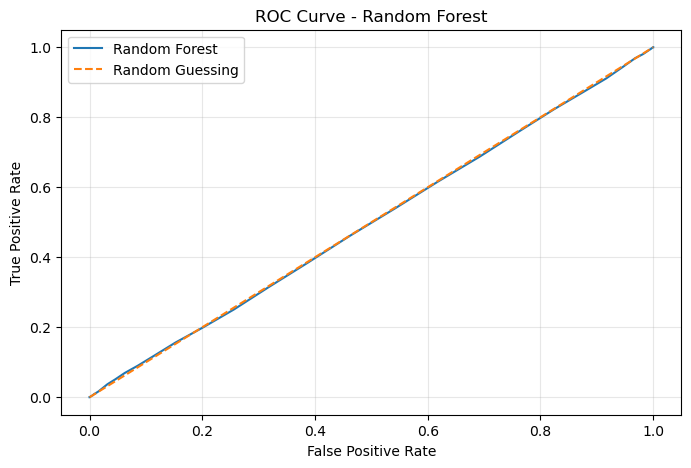

In [121]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 5))

plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [122]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_prepared, y_train)

print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


In [123]:
y_pred_gb = gb_model.predict(X_test_prepared)

print("Gradient Boosting Predictions:")
print(y_pred_gb[:20])

print("\nActual Values:")
print(y_test[:20].values)

Gradient Boosting Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Actual Values:
[0 1 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0]


In [124]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_gb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Accuracy: 0.799470345507175

Confusion Matrix:
[[38943     3]
 [ 9765     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     38946
           1       0.00      0.00      0.00      9765

    accuracy                           0.80     48711
   macro avg       0.40      0.50      0.44     48711
weighted avg       0.64      0.80      0.71     48711



In [125]:
from sklearn.metrics import roc_auc_score

y_prob_gb = gb_model.predict_proba(X_test_prepared)[:, 1]

roc_auc_gb = roc_auc_score(y_test, y_prob_gb)

print("Gradient Boosting ROC-AUC:", roc_auc_gb)

Gradient Boosting ROC-AUC: 0.497559441935029


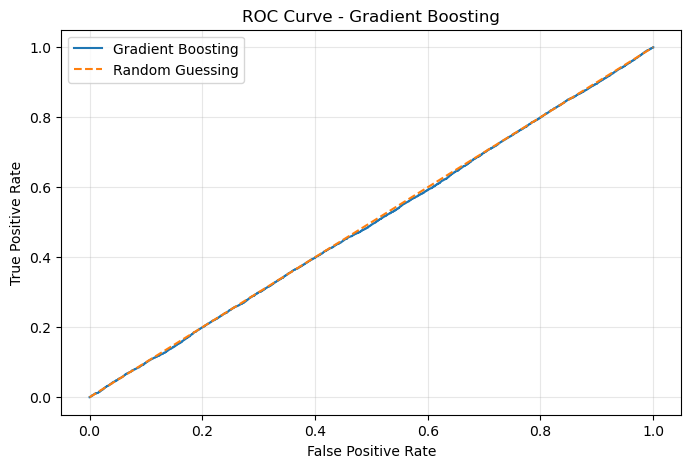

In [126]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_gb, tpr_gb, thresholds_gb = roc_curve(y_test, y_prob_gb)

plt.figure(figsize=(8, 5))

plt.plot(fpr_gb, tpr_gb, label="Gradient Boosting")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.title("ROC Curve - Gradient Boosting")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

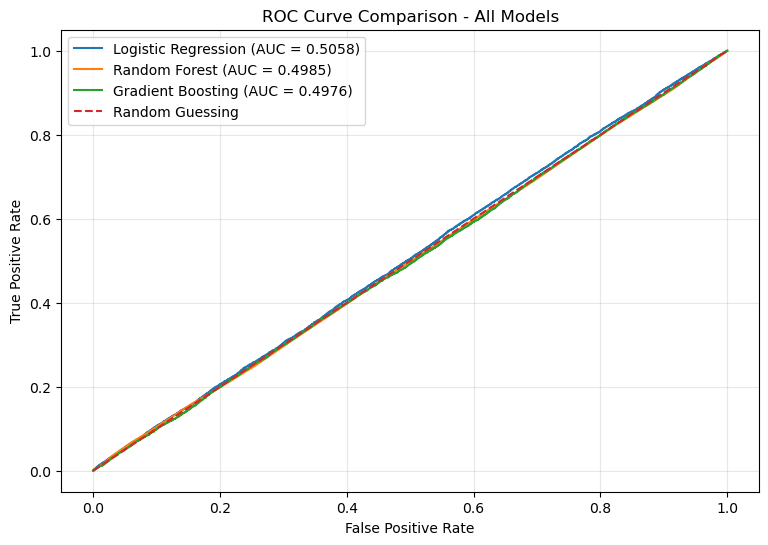

In [127]:
plt.figure(figsize=(9, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_lr:.4f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_rf:.4f})")
plt.plot(fpr_gb, tpr_gb, label=f"Gradient Boosting (AUC = {roc_auc_gb:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.title("ROC Curve Comparison - All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [128]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

results = []

models = [
    ("Logistic Regression", y_pred_lr, y_prob_lr),
    ("Random Forest", y_pred_rf, y_prob_rf),
    ("Gradient Boosting", y_pred_gb, y_prob_gb)
]

for name, predictions, probabilities in models:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "Average Precision": average_precision_score(y_test, probabilities)
    })

model_comparison = pd.DataFrame(results)

print(model_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  \
0  Logistic Regression    0.7995        0.0     0.0       0.0   0.5058   
1        Random Forest    0.7995        0.0     0.0       0.0   0.4985   
2    Gradient Boosting    0.7995        0.0     0.0       0.0   0.4976   

   Average Precision  
0             0.2051  
1             0.2014  
2             0.1994  


In [129]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_prepared, y_train)

y_pred_dummy = dummy_model.predict(X_test_prepared)
y_prob_dummy = dummy_model.predict_proba(X_test_prepared)[:, 1]

print("Baseline Accuracy:", accuracy_score(y_test, y_pred_dummy))
print("Baseline ROC-AUC:", roc_auc_score(y_test, y_prob_dummy))
print("Baseline Average Precision:", average_precision_score(y_test, y_prob_dummy))

Baseline Accuracy: 0.7995319332388988
Baseline ROC-AUC: 0.5
Baseline Average Precision: 0.20046806676110118


In [130]:
baseline_results = {
    "Model": "Baseline",
    "Accuracy": accuracy_score(y_test, y_pred_dummy),
    "Precision": precision_score(y_test, y_pred_dummy, zero_division=0),
    "Recall": recall_score(y_test, y_pred_dummy, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_dummy, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_dummy),
    "Average Precision": average_precision_score(y_test, y_prob_dummy)
}

model_comparison = pd.concat(
    [model_comparison, pd.DataFrame([baseline_results])],
    ignore_index=True
)

print("Final Model Comparison:")
print(model_comparison.round(4))


Final Model Comparison:
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  \
0  Logistic Regression    0.7995        0.0     0.0       0.0   0.5058   
1        Random Forest    0.7995        0.0     0.0       0.0   0.4985   
2    Gradient Boosting    0.7995        0.0     0.0       0.0   0.4976   
3             Baseline    0.7995        0.0     0.0       0.0   0.5000   

   Average Precision  
0             0.2051  
1             0.2014  
2             0.1994  
3             0.2005  


In [131]:
model_comparison.to_csv(
    "customer_churn_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


### Model Evaluation – Conclusion

Three machine learning algorithms were trained and evaluated: Logistic Regression, Random Forest, and Gradient Boosting.

A Baseline model was also created for performance comparison.

All three machine learning models achieved approximately 79.95% accuracy. However, their precision, recall, and F1-score for the churn class were zero at the default classification threshold.

The ROC-AUC scores were:
- Logistic Regression: 0.5058
- Random Forest: 0.4985
- Gradient Boosting: 0.4976
- Baseline: 0.5000

Logistic Regression performed marginally better than the other models, but its predictive performance was still very weak.

**Final Finding:** None of the trained models demonstrated reliable customer churn prediction. Further investigation of the dataset, target variable, and feature quality is required before developing a reliable predictive solution.

In [132]:
feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance.head(15))

Top 15 Important Features:
                              Feature  Importance
2               num__estimated_salary    0.126793
5                      num__data_used    0.126749
3                     num__calls_made    0.114367
4                       num__sms_sent    0.106805
0                            num__age    0.104829
7             num__registration_month    0.071329
1                 num__num_dependents    0.044924
6              num__registration_year    0.037655
11      cat__telecom_partner_Vodafone    0.011585
9           cat__telecom_partner_BSNL    0.011489
10  cat__telecom_partner_Reliance Jio    0.011317
8         cat__telecom_partner_Airtel    0.010648
42                cat__city_Bangalore    0.010110
47                   cat__city_Mumbai    0.010101
43                  cat__city_Chennai    0.010080


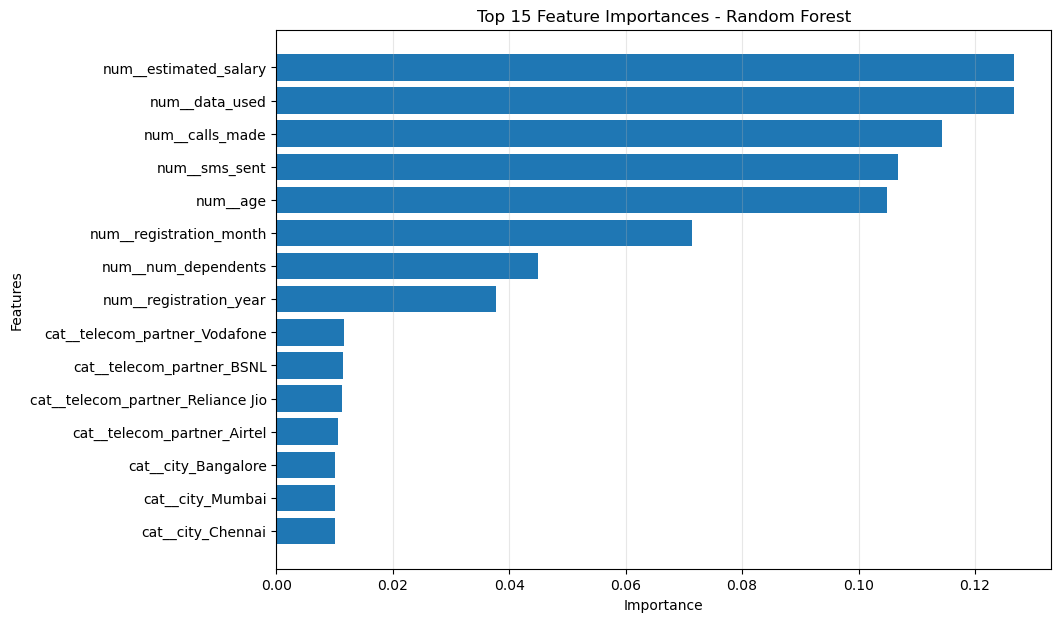

In [133]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.grid(axis="x", alpha=0.3)

plt.show()

### Feature Importance Analysis

Random Forest feature importance was used to identify the features contributing most to the model's decisions.

The top features were estimated_salary, data_used, calls_made, sms_sent, and age.

Categorical features such as telecom_partner and city showed relatively low individual importance.

However, the Random Forest model achieved a ROC-AUC score of approximately 0.498, indicating very weak predictive performance. Therefore, feature importance rankings should be interpreted cautiously and do not establish a reliable relationship with customer churn.

In [134]:
numerical_features = [
    "age",
    "num_dependents",
    "estimated_salary",
    "calls_made",
    "sms_sent",
    "data_used",
    "registration_year",
    "registration_month"
]

print("Average Numerical Features by Churn:")

print(
    df.groupby("churn")[numerical_features]
    .mean()
    .round(2)
)

Average Numerical Features by Churn:
         age  num_dependents  estimated_salary  calls_made  sms_sent  \
churn                                                                  
0      46.07            2.00          85083.73       48.99     23.97   
1      46.11            1.99          84771.53       49.11     23.86   

       data_used  registration_year  registration_month  
churn                                                    
0        4992.11             2021.2                6.12  
1        4997.49             2021.2                6.13  


In [135]:
correlation = df[numerical_features + ["churn"]].corr()

print("Correlation with Churn:")
print(
    correlation["churn"]
    .sort_values(ascending=False)
)

Correlation with Churn:
churn                 1.000000
registration_month    0.001783
calls_made            0.001692
registration_year     0.001114
age                   0.000839
data_used             0.000732
num_dependents       -0.002543
sms_sent             -0.003072
estimated_salary     -0.003332
Name: churn, dtype: float64


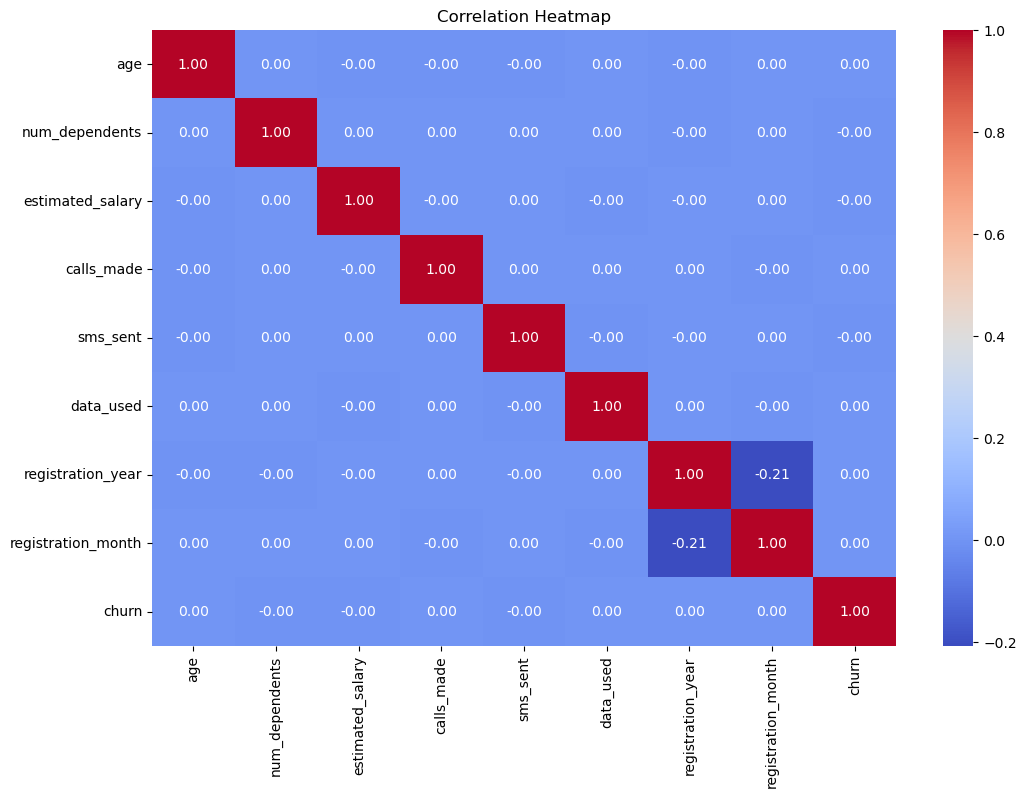

In [136]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [137]:
categorical_features = [
    "telecom_partner",
    "gender",
    "state",
    "city"
]

for col in categorical_features:
    print(f"\nChurn Rate by {col}:")
    print(
        df.groupby(col)["churn"]
        .mean()
        .mul(100)
        .round(2)
        .sort_values(ascending=False)
    )


Churn Rate by telecom_partner:
telecom_partner
Airtel          20.37
Reliance Jio    20.02
Vodafone        19.95
BSNL            19.86
Name: churn, dtype: float64

Churn Rate by gender:
gender
F    20.30
M    19.88
Name: churn, dtype: float64

Churn Rate by state:
state
Jharkhand            21.12
Karnataka            20.71
Mizoram              20.65
Uttarakhand          20.42
Himachal Pradesh     20.41
Madhya Pradesh       20.38
Assam                20.30
Odisha               20.25
Nagaland             20.23
Rajasthan            20.22
Telangana            20.11
Manipur              20.11
Uttar Pradesh        20.08
Sikkim               20.07
Haryana              20.03
Gujarat              20.02
Goa                  19.96
Tamil Nadu           19.94
Maharashtra          19.91
Arunachal Pradesh    19.89
Andhra Pradesh       19.85
Meghalaya            19.75
Bihar                19.63
Kerala               19.53
Tripura              19.48
Punjab               19.43
Chhattisgarh         19.43

### Investigation of Weak Model Performance

The investigation identified the following observations:

1. The dataset contains approximately 79.95% non-churn customers and 20.05% churn customers.
2. Average numerical feature values are very similar for churned and non-churned customers.
3. Numerical feature correlations with churn are extremely close to zero.
4. Categorical feature churn rates show only small differences.
5. All three machine learning models achieved ROC-AUC scores close to 0.50.

### Conclusion

The available features show very limited predictive relationships with the churn target. This may explain the weak performance of the trained models.

Further investigation of the dataset source, target generation process, and feature definitions is required before making business recommendations.

In [138]:
print("Unique Churn Values:")
print(df["churn"].unique())

print("\nChurn Value Counts:")
print(df["churn"].value_counts())

print("\nChurn Data Type:")
print(df["churn"].dtype)

print("\nMissing Churn Values:")
print(df["churn"].isnull().sum())

Unique Churn Values:
[0 1]

Churn Value Counts:
churn
0    194726
1     48827
Name: count, dtype: int64

Churn Data Type:
int64

Missing Churn Values:
0


In [139]:
id_groups = pd.qcut(
    df["customer_id"],
    q=10,
    duplicates="drop"
)

id_churn = df.groupby(
    id_groups,
    observed=True
)["churn"].agg(["count", "mean"])

id_churn["churn_rate_%"] = (
    id_churn["mean"] * 100
)

print("Churn Rate Across Customer ID Ranges:")
display(id_churn.round(2))

Churn Rate Across Customer ID Ranges:


,count,mean,churn_rate_%
customer_id,,,
"(0.999, 24356.2]",24356,0.2,19.74
"(24356.2, 48711.4]",24355,0.2,20.04
"(48711.4, 73066.6]",24355,0.2,19.93
"(73066.6, 97421.8]",24355,0.2,20.18
"(97421.8, 121777.0]",24356,0.2,19.99
"(121777.0, 146132.2]",24355,0.2,20.36
"(146132.2, 170487.4]",24355,0.2,20.11
"(170487.4, 194842.6]",24355,0.2,19.98
"(194842.6, 219197.8]",24355,0.2,20.16


In [140]:
print("Churn Rate by Customer ID Order:")

df_sorted = df.sort_values("customer_id").copy()

df_sorted["id_group"] = pd.qcut(
    df_sorted["customer_id"],
    q=20,
    labels=False,
    duplicates="drop"
)

print(
    df_sorted.groupby("id_group", observed=True)["churn"]
    .agg(["count", "mean"])
    .assign(
        churn_rate=lambda x: (x["mean"] * 100).round(2)
    )
)

Churn Rate by Customer ID Order:
          count      mean  churn_rate
id_group                             
0         12178  0.199622       19.96
1         12178  0.195270       19.53
2         12177  0.197257       19.73
3         12178  0.203564       20.36
4         12178  0.196091       19.61
5         12177  0.202431       20.24
6         12178  0.202989       20.30
7         12177  0.200542       20.05
8         12178  0.200033       20.00
9         12178  0.199787       19.98
10        12177  0.201774       20.18
11        12178  0.205370       20.54
12        12177  0.203334       20.33
13        12178  0.198801       19.88
14        12178  0.200361       20.04
15        12177  0.199146       19.91
16        12178  0.199458       19.95
17        12177  0.203827       20.38
18        12178  0.200443       20.04
19        12178  0.199458       19.95


In [141]:
df["registration_date_only"] = (
    df["date_of_registration"].dt.to_period("Q")
)

quarterly_churn = df.groupby(
    "registration_date_only",
    observed=True
)["churn"].agg(["count", "mean"])

quarterly_churn["churn_rate_%"] = (
    quarterly_churn["mean"] * 100
)

display(quarterly_churn.round(2))

,count,mean,churn_rate_%
registration_date_only,,,
2020Q1,18182,0.2,19.59
2020Q2,18181,0.2,19.86
2020Q3,18382,0.2,19.98
2020Q4,18381,0.2,20.21
2021Q1,17982,0.2,20.14
2021Q2,18181,0.2,20.09
2021Q3,18381,0.2,20.13
2021Q4,18382,0.2,20.31
2022Q1,17981,0.2,20.16


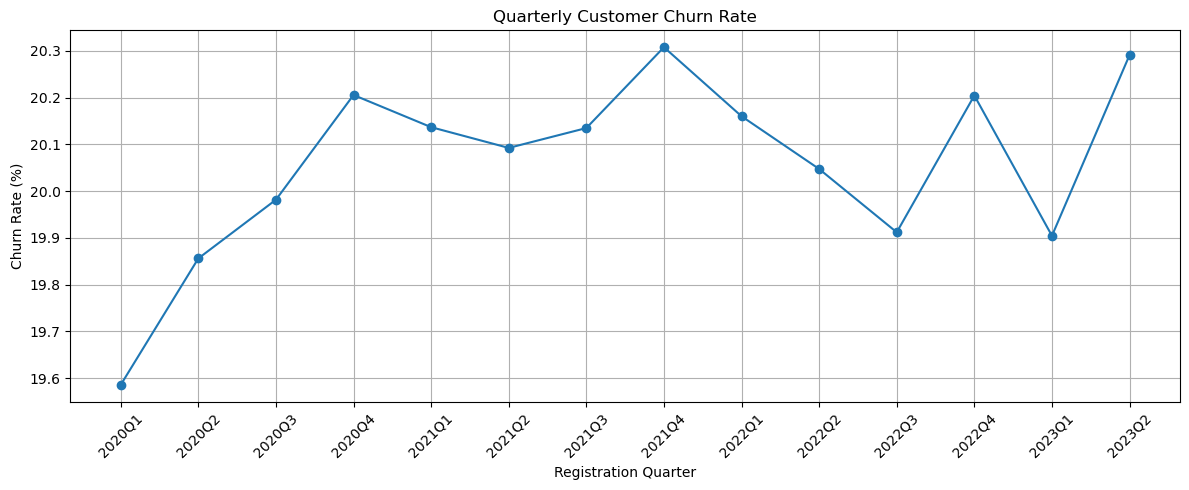

In [142]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    quarterly_churn.index.astype(str),
    quarterly_churn["churn_rate_%"],
    marker="o"
)

plt.title("Quarterly Customer Churn Rate")
plt.xlabel("Registration Quarter")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [143]:
print("Earliest Registration Date:")
print(df["date_of_registration"].min())

print("\nLatest Registration Date:")
print(df["date_of_registration"].max())

print("\nMonthly Record Counts:")
monthly_counts = df.groupby(
    df["date_of_registration"].dt.to_period("M")
).size()

display(monthly_counts.tail(12))

Earliest Registration Date:
2020-01-01 00:00:00

Latest Registration Date:
2023-05-04 00:00:00

Monthly Record Counts:


date_of_registration
2022-06    5994
2022-07    6194
2022-08    6193
2022-09    5994
2022-10    6194
2022-11    5994
2022-12    6194
2023-01    6193
2023-02    5595
2023-03    6193
2023-04    5994
2023-05     600
Freq: M, dtype: int64

In [144]:
monthly_churn = df.groupby(
    df["date_of_registration"].dt.to_period("M")
)["churn"].agg(["count", "mean"])

monthly_churn["churn_rate_%"] = (
    monthly_churn["mean"] * 100
)

display(monthly_churn.tail(12).round(2))

,count,mean,churn_rate_%
date_of_registration,,,
2022-06,5994,0.20,20.20
2022-07,6194,0.20,19.58
2022-08,6193,0.20,20.22
2022-09,5994,0.20,19.94
2022-10,6194,0.20,19.87
2022-11,5994,0.21,20.62
2022-12,6194,0.20,20.13
2023-01,6193,0.20,20.04
2023-02,5595,0.20,20.41


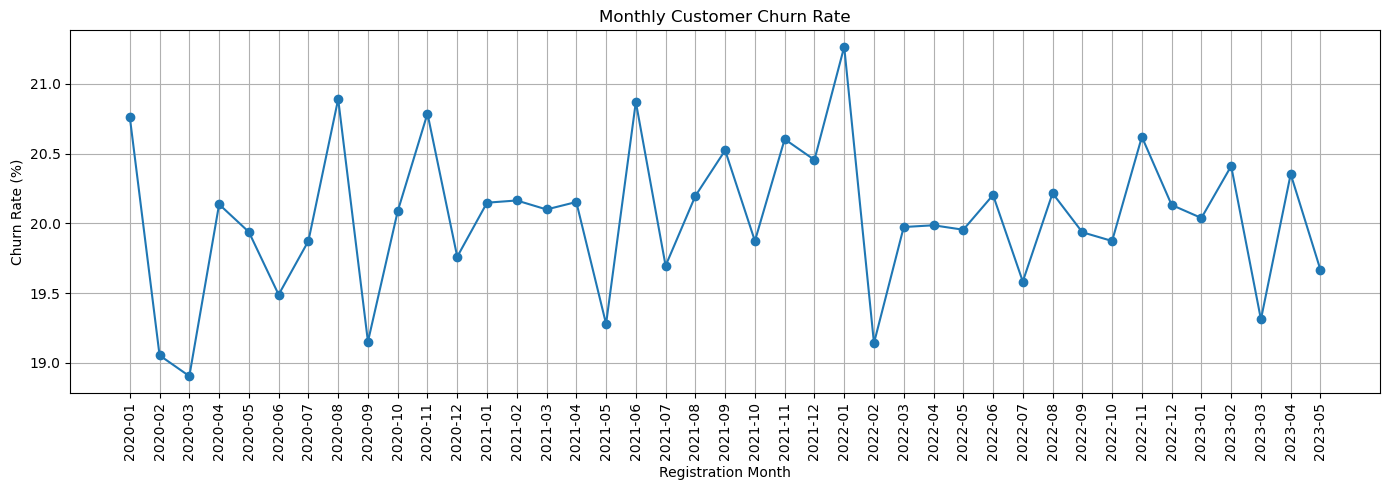

In [145]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_churn.index.astype(str),
    monthly_churn["churn_rate_%"],
    marker="o"
)

plt.title("Monthly Customer Churn Rate")
plt.xlabel("Registration Month")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

### Monthly Customer Churn Analysis – Conclusion

- Monthly churn rates fluctuate across the registration period.
- Most monthly churn rates remain close to the overall churn rate of 20.05%.
- No consistent increasing or decreasing trend is observed.
- May 2023 contains only 600 records, indicating an incomplete month.
- Registration month alone does not show a strong relationship with customer churn.

Therefore, monthly registration patterns provide limited predictive information about customer churn.

## Overall Investigation of Customer Churn Patterns

1. Customer ID ranges show similar churn rates, with no obvious pattern.
2. Churn rates across registration quarters remain close to 20%.
3. Monthly churn rates fluctuate slightly without a consistent trend.
4. Registration year and month provide limited predictive information.
5. Correlation and Mutual Information results show very weak relationships between available features and churn.
6. The three trained machine learning models perform close to the baseline model.

### Final Observation

The available features do not appear to contain enough predictive information to reliably identify customer churn.

Further investigation of the dataset source, target variable generation process, and business meaning of the features is required before final model development.

## Dataset Approval

The Customer Churn dataset containing 243,553 records and 14 original columns was confirmed by the DataMites mentor as the approved dataset for this project.

All subsequent analysis and model development are based on this approved dataset.

In [146]:
print("Missing Values in Each Column:")

display(
    df.isnull().sum().to_frame(
        name="Missing Values"
    )
)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values in Each Column:


,Missing Values
customer_id,0
telecom_partner,0
gender,0
age,0
state,0
city,0
pincode,0
date_of_registration,0
num_dependents,0
estimated_salary,0



Total Missing Values: 0


In [147]:
# Close the old connection safely
try:
    connection.rollback()
except Exception:
    pass

try:
    connection.close()
except Exception:
    pass

# Reset old database connections
engine.dispose()

# Create a fresh connection
connection = engine.connect()

# Load the customer churn dataset
df = pd.read_sql(
    "SELECT * FROM telecom_churn_data",
    connection
)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())



Dataset loaded successfully!
Dataset shape: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [148]:
df = pd.read_sql(
    "SELECT * FROM telecom_churn_data",
    connection
)

In [149]:
print("Dataset shape:", df.shape)
print("Total columns:", len(df.columns))
print("Dataset available:", isinstance(df, pd.DataFrame))

Dataset shape: (243553, 14)
Total columns: 14
Dataset available: True


In [150]:
print("df_model shape:", df_model.shape)
print("\nColumns:")
print(df_model.columns.tolist())

df_model shape: (243553, 13)

Columns:
['telecom_partner', 'gender', 'age', 'state', 'city', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn', 'registration_year', 'registration_month']


In [151]:
print("Training data:", X_train_prepared.shape)
print("Testing data:", X_test_prepared.shape)

print("\nLogistic Regression:", hasattr(lr_model, "classes_"))
print("Random Forest:", hasattr(rf_model, "classes_"))
print("Gradient Boosting:", hasattr(gb_model, "classes_"))

Training data: (194842, 48)
Testing data: (48711, 48)

Logistic Regression: True
Random Forest: True
Gradient Boosting: True


In [152]:
print("Preprocessor available:", hasattr(preprocessor, "transform"))
print("Training data shape:", X_train_prepared.shape)
print("Testing data shape:", X_test_prepared.shape)

Preprocessor available: True
Training data shape: (194842, 48)
Testing data shape: (48711, 48)
